# Classificação do Tipo de Cobertura Florestal (Forest Cover Type Prediction)

**Disciplina:** Reconhecimento de Padrões, PPCOMP/IFES
**Autor:** Arthur Delpupo
**Desafio Kaggle:** [Forest Cover Type Prediction](https://www.kaggle.com/c/forest-cover-type-prediction)

## Resultado em resumo

Prevejo a espécie de árvore predominante (7 classes) em áreas de 30 × 30 m a partir de dados cartográficos. O modelo final é um **Extra Trees** com features de distância e elevação criadas neste trabalho.

| Etapa | Acurácia |
|---|---|
| Baseline (sempre a mesma classe) | 14,3% |
| Melhor modelo sem as features novas (validação cruzada) | 85,5% |
| Modelo final (validação cruzada) | 89,5% |
| **Modelo final no teste guardado** (usado uma única vez) | **89,9%** |
| **Nota no Kaggle** (teste com a distribuição real das espécies) | **80,6%** |

A nota do Kaggle é menor porque o teste dele é dominado pelas duas espécies mais difíceis de separar, e não por sobreajuste (seção 7.6).

## Sumário
1. Introdução
2. Exploração inicial
3. Preparação dos dados
4. Exploração e visualização dos dados
5. Engenharia e seleção de features
6. Modelagem, comparação e validação cruzada
7. Avaliação dos resultados
8. Conclusão e próximos passos
9. Reprodutibilidade

## 1. Introdução

**Problema.** Prever a espécie de árvore predominante em áreas de 30 × 30 m usando só variáveis cartográficas (relevo, distâncias, sombreamento, área e solo), sem imagens nem observação da vegetação. Um modelo assim permite estimar a vegetação de grandes áreas sem inventário de campo, que é caro e lento.

**Dados.** A competição do Kaggle usa o dataset Covertype (Blackard e Dean, 1999, UCI). As áreas ficam em quatro áreas selvagens da Roosevelt National Forest, no Colorado (EUA): Rawah (1), Neota (2), Comanche Peak (3) e Cache la Poudre (4). Por terem pouca interferência humana, a vegetação reflete principalmente o terreno.

| Classe | Espécie | Onde ocorre |
|---|---|---|
| 1 | Spruce/Fir | Floresta subalpina, altitudes altas |
| 2 | Lodgepole Pine | Altitude média a alta, comum após incêndios |
| 3 | Ponderosa Pine | Altitudes baixas, encostas secas |
| 4 | Cottonwood/Willow | Junto a cursos d'água |
| 5 | Aspen | Faixas intermediárias |
| 6 | Douglas-fir | Altitudes baixas a médias |
| 7 | Krummholz | Limite superior das árvores |

| Grupo de features | Colunas |
|---|---|
| Relevo | `Elevation` (m), `Aspect` (graus a partir do norte), `Slope` (graus) |
| Distâncias (m) | horizontal e vertical até a água, horizontal até estradas e até pontos de ignição de incêndios |
| Sombreamento | `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` (índice de 0 a 255) |
| Binárias (one-hot) | 4 áreas selvagens e 40 tipos de solo |

O `train.csv` tem 15.120 áreas rotuladas; o `test.csv`, 565.892 sem rótulo, para a submissão.

**Métrica.** Acurácia, a métrica oficial. Ela é adequada porque o treino é balanceado (seção 2.6). Acompanho também precisão, recall, F1 e AUC-ROC.

### 1.1 Configuração do ambiente

Importo as bibliotecas e fixo a semente aleatória para garantir reprodutibilidade.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, label_binarize

warnings.filterwarnings("ignore", category=FutureWarning)
# O joblib às vezes reinicia processos auxiliares durante tarefas paralelas e emite este aviso.
# Ele não altera nenhum resultado, então o silencio para manter as saídas limpas.
warnings.filterwarnings("ignore", message="A worker stopped")

# Semente única usada em toda aleatoriedade do notebook (split, CV, modelos)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Os dados não são versionados no repositório (regras da competição); ver README
DATA_DIR = Path("data")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

### 1.2 Carregamento dos dados

Só o `train.csv` tem rótulos. O `test.csv` é usado apenas na submissão ao Kaggle (seção 7.7).

In [2]:
# Carrego o treino (com rótulos) e, se disponível, o teste do Kaggle (sem rótulos)
train_path = DATA_DIR / "train.csv"
test_path = DATA_DIR / "test.csv"

if not train_path.exists():
    raise FileNotFoundError(
        "Arquivo data/train.csv não encontrado. Baixe os dados seguindo o passo a passo do README."
    )

df = pd.read_csv(train_path)
df_test_kaggle = pd.read_csv(test_path) if test_path.exists() else None

print(f"Treino: {df.shape[0]} linhas x {df.shape[1]} colunas")
if df_test_kaggle is not None:
    print(f"Teste Kaggle: {df_test_kaggle.shape[0]} linhas x {df_test_kaggle.shape[1]} colunas")
df.head()

Treino: 15120 linhas x 56 colunas
Teste Kaggle: 565892 linhas x 55 colunas


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


## 2. Exploração inicial

Verifico tipos, estatísticas, faltantes, duplicatas e balanceamento, para saber o que tratar na seção 3. São checagens descritivas; os gráficos que orientam decisões (seção 4) usam só a parte de treino.

In [3]:
# Agrupo as colunas por tipo para reutilizar ao longo do notebook
NUM_COLS = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]
WILD_COLS = [col for col in df.columns if col.startswith("Wilderness_Area")]
SOIL_COLS = [col for col in df.columns if col.startswith("Soil_Type")]
TARGET = "Cover_Type"

print(f"{len(NUM_COLS)} numéricas, {len(WILD_COLS)} de área selvagem, {len(SOIL_COLS)} de solo")

10 numéricas, 4 de área selvagem, 40 de solo


### 2.1 Estrutura e tipos das colunas

In [4]:
# Tipos das colunas, contagem de não nulos e uso de memória
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15120 non-null  int64
 12  Wilderness_Area

Todas as colunas são inteiras e as 44 binárias já estão em one-hot: não há conversão a fazer. O `Id` é só um número de linha e será removido.

### 2.2 Estatísticas descritivas das variáveis numéricas

In [5]:
# Estatísticas básicas + assimetria das variáveis numéricas
desc = df[NUM_COLS].describe().T
desc["assimetria"] = df[NUM_COLS].skew()
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,assimetria
Elevation,15120.0,2749.3,417.7,1863.0,2376.0,2752.0,3104.0,3849.0,0.1
Aspect,15120.0,156.7,110.1,0.0,65.0,126.0,261.0,360.0,0.5
Slope,15120.0,16.5,8.5,0.0,10.0,15.0,22.0,52.0,0.5
Horizontal_Distance_To_Hydrology,15120.0,227.2,210.1,0.0,67.0,180.0,330.0,1343.0,1.5
Vertical_Distance_To_Hydrology,15120.0,51.1,61.2,-146.0,5.0,32.0,79.0,554.0,1.5
Horizontal_Distance_To_Roadways,15120.0,1714.0,1325.1,0.0,764.0,1316.0,2270.0,6890.0,1.2
Hillshade_9am,15120.0,212.7,30.6,0.0,196.0,220.0,235.0,254.0,-1.1
Hillshade_Noon,15120.0,219.0,22.8,99.0,207.0,223.0,235.0,254.0,-1.0
Hillshade_3pm,15120.0,135.1,45.9,0.0,106.0,138.0,167.0,248.0,-0.3
Horizontal_Distance_To_Fire_Points,15120.0,1511.1,1099.9,0.0,730.0,1256.0,1988.2,6993.0,1.6


In [6]:
# Contagem de valores negativos e de zeros, para identificar valores possivelmente suspeitos
pd.DataFrame({
    "negativos": (df[NUM_COLS] < 0).sum(),
    "zeros": (df[NUM_COLS] == 0).sum(),
})

,negativos,zeros
Elevation,0,0
Aspect,0,110
Slope,0,5
Horizontal_Distance_To_Hydrology,0,1590
Vertical_Distance_To_Hydrology,1139,1890
Horizontal_Distance_To_Roadways,0,3
Hillshade_9am,0,1
Hillshade_Noon,0,0
Hillshade_3pm,0,88
Horizontal_Distance_To_Fire_Points,0,2


- **Escalas muito diferentes** (elevação até 3.849 m, distâncias até ~7.000 m, `Slope` até 52°): KNN e regressão logística precisarão de padronização (seção 3.4).
- **Distâncias com cauda longa à direita** (assimetria acima de 1,2).
- **1.139 valores negativos em `Vertical_Distance_To_Hydrology`:** válidos, indicam ponto abaixo do nível da água.
- **88 zeros em `Hillshade_3pm`:** podem ser sombra real ou valor faltante; investigo na seção 4.4.
- **`Aspect` é circular** (0° = 360°): trato na seção 5.

### 2.3 Consistência das colunas binárias

Confiro se cada linha tem exatamente uma área selvagem e um tipo de solo, como exige o one-hot.

In [7]:
binarias = WILD_COLS + SOIL_COLS
print("Todas as binárias contêm apenas 0 e 1:", df[binarias].isin([0, 1]).all().all())
print("Linhas com exatamente 1 área selvagem:", (df[WILD_COLS].sum(axis=1) == 1).all())
print("Linhas com exatamente 1 tipo de solo:", (df[SOIL_COLS].sum(axis=1) == 1).all())

# Tipos de solo raros no treino (menos de 20 ocorrências)
contagem_solo = df[SOIL_COLS].sum().sort_values()
contagem_solo[contagem_solo < 20]

Todas as binárias contêm apenas 0 e 1: True
Linhas com exatamente 1 área selvagem: True
Linhas com exatamente 1 tipo de solo: True


Soil_Type15     0
Soil_Type7      0
Soil_Type8      1
Soil_Type25     1
Soil_Type28     9
Soil_Type36    10
Soil_Type9     10
Soil_Type27    15
Soil_Type21    16
dtype: int64

A codificação está correta. `Soil_Type7` e `Soil_Type15` nunca aparecem no treino (colunas constantes, removidas na seção 3.2), e vários solos são raros.

### 2.4 Dados faltantes

In [8]:
faltantes_treino = df.isnull().sum()
print("Valores faltantes no treino:", faltantes_treino.sum())

if df_test_kaggle is not None:
    print("Valores faltantes no teste do Kaggle:", df_test_kaggle.isnull().sum().sum())

# Lista as colunas com faltantes, se houver alguma
faltantes_treino[faltantes_treino > 0]

Valores faltantes no treino: 0
Valores faltantes no teste do Kaggle: 0


Series([], dtype: int64)

Nenhum valor faltante no treino nem no teste. Mesmo assim, incluo um imputador no pipeline (seção 3.1).

### 2.5 Linhas duplicadas

O critério mais importante é o último: linhas com features iguais e classes diferentes seriam ruído impossível de separar.

In [9]:
# Procuro duplicatas de três formas: linha inteira, sem o Id e só nas features
features = df.drop(columns=["Id", TARGET])

print("Linhas duplicadas (completas):", df.duplicated().sum())
print("Linhas duplicadas (sem Id):", df.drop(columns="Id").duplicated().sum())
print("Linhas com features idênticas:", features.duplicated().sum())

Linhas duplicadas (completas): 0
Linhas duplicadas (sem Id): 0
Linhas com features idênticas: 0


Nenhuma duplicata. Não há risco de a mesma área cair no treino e na validação.

### 2.6 Balanceamento das classes

In [10]:
# Nomes das espécies, reutilizados nos gráficos e relatórios das próximas seções
COVER_NAMES = {
    1: "Spruce/Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood/Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz",
}

contagem_classes = df[TARGET].value_counts().sort_index()
pd.DataFrame({
    "espécie": contagem_classes.index.map(COVER_NAMES),
    "amostras": contagem_classes.values,
    "proporção (%)": (contagem_classes.values / len(df) * 100).round(2),
}, index=contagem_classes.index)

,espécie,amostras,proporção (%)
Cover_Type,,,
1,Spruce/Fir,2160,14.29
2,Lodgepole Pine,2160,14.29
3,Ponderosa Pine,2160,14.29
4,Cottonwood/Willow,2160,14.29
5,Aspen,2160,14.29
6,Douglas-fir,2160,14.29
7,Krummholz,2160,14.29


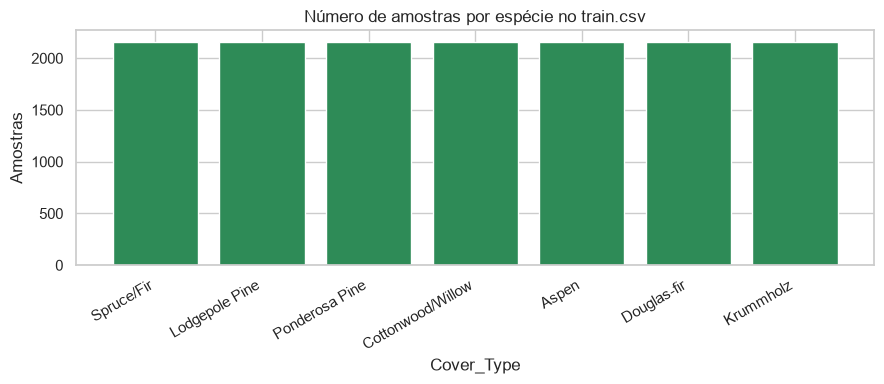

In [11]:
# Gráfico de barras com o número de amostras por espécie
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([COVER_NAMES[c] for c in contagem_classes.index], contagem_classes.values, color="seagreen")
ax.set_title("Número de amostras por espécie no train.csv")
ax.set_xlabel("Cover_Type")
ax.set_ylabel("Amostras")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Todas as classes têm exatamente 2.160 linhas. Por isso:

- a **acurácia é adequada** como métrica principal, e o **baseline é 14,3%** (1/7);
- não é preciso rebalancear.

**Atenção:** o balanceamento é artificial. O teste do Kaggle segue a distribuição real da floresta, dominada por Spruce/Fir e Lodgepole Pine. Isso explica a nota do Kaggle (seção 7.6).

## 3. Preparação dos dados

Regra geral: tudo o que é aprendido dos dados (medianas, médias, desvios) fica dentro de um `Pipeline` e é ajustado só no treino de cada fold. Isso evita vazamento de dados, que deixaria as métricas otimistas.

### 3.1 Tratamento de dados faltantes

Não há faltantes (seção 2.4), mas incluo um `SimpleImputer` no pipeline por robustez: em produção, um dado incompleto quebraria o modelo. Sem faltantes, ele não altera nada.

- **Numéricas: mediana**, porque as distâncias têm cauda longa e a média seria puxada pelos extremos.
- **Binárias: valor mais frequente**, para manter 0 ou 1.

### 3.2 Remoção de colunas sem informação

Removo o `Id` (número de linha, sem significado físico) e as colunas constantes, que não ajudam a separar nenhuma classe.

In [12]:
# Colunas com um único valor em todo o train.csv
CONST_COLS = [col for col in df.columns if df[col].nunique() == 1]
print("Colunas constantes:", CONST_COLS)

# Quantas linhas do teste do Kaggle têm esses tipos de solo
if df_test_kaggle is not None:
    for col in CONST_COLS:
        n = df_test_kaggle[col].sum()
        print(f"{col} no teste do Kaggle: {n} linhas ({n / len(df_test_kaggle):.3%})")

Colunas constantes: ['Soil_Type7', 'Soil_Type15']
Soil_Type7 no teste do Kaggle: 105 linhas (0.019%)
Soil_Type15 no teste do Kaggle: 3 linhas (0.001%)


Os solos 7 e 15 aparecem em só 108 linhas do teste do Kaggle (0,02%). Como o modelo nunca os viu no treino, não teria como aprender algo sobre eles; nessas linhas, decide pelas outras features. O `df_test_kaggle` fica intacto até a submissão.

In [13]:
COLS_REMOVIDAS = ["Id"] + CONST_COLS

X = df.drop(columns=COLS_REMOVIDAS + [TARGET])
y = df[TARGET]

# Listas de colunas atualizadas, sem as constantes
BIN_COLS = [col for col in WILD_COLS + SOIL_COLS if col not in CONST_COLS]

print(f"X: {X.shape[0]} linhas x {X.shape[1]} colunas ({len(NUM_COLS)} numéricas + {len(BIN_COLS)} binárias)")

X: 15120 linhas x 52 colunas (10 numéricas + 42 binárias)


### 3.3 Divisão em treino e teste

- **80% treino (12.096 linhas):** exploração, features e comparação de modelos com validação cruzada.
- **20% teste (3.024 linhas):** guardados e usados **uma única vez**, na seção 7, para uma estimativa honesta.

Uso `stratify=y` para manter as proporções de classe. Em vez de um conjunto fixo de validação, uso validação cruzada estratificada de 5 folds nos 80%: aproveita melhor os dados e dá o desvio padrão das métricas.

In [14]:
# Divisão 80/20 estratificada; os 20% de teste ficam guardados até a seção 7
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape[0]} linhas | Teste guardado: {X_test.shape[0]} linhas")

Treino: 12096 linhas | Teste guardado: 3024 linhas


In [15]:
# Confere a estratificação: as duas partes devem ter as mesmas proporções por classe
proporcoes = pd.DataFrame({
    "espécie": [COVER_NAMES[c] for c in sorted(COVER_NAMES)],
    "treino": y_train.value_counts().sort_index().values,
    "teste": y_test.value_counts().sort_index().values,
}, index=sorted(COVER_NAMES))
proporcoes["treino (%)"] = (proporcoes["treino"] / len(y_train) * 100).round(2)
proporcoes["teste (%)"] = (proporcoes["teste"] / len(y_test) * 100).round(2)
proporcoes

,espécie,treino,teste,treino (%),teste (%)
1,Spruce/Fir,1728,432,14.29,14.29
2,Lodgepole Pine,1728,432,14.29,14.29
3,Ponderosa Pine,1728,432,14.29,14.29
4,Cottonwood/Willow,1728,432,14.29,14.29
5,Aspen,1728,432,14.29,14.29
6,Douglas-fir,1728,432,14.29,14.29
7,Krummholz,1728,432,14.29,14.29


In [16]:
# Depois da divisão, nenhuma coluna pode ter ficado constante no treino
const_no_treino = [col for col in X_train.columns if X_train[col].nunique() == 1]
print("Colunas constantes em X_train:", const_no_treino or "nenhuma")

Colunas constantes em X_train: nenhuma


A estratificação funcionou (1.728 e 432 linhas por classe) e nenhuma coluna ficou constante no treino. Abaixo, defino a validação cruzada usada no resto do notebook.

In [17]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def avaliar_cv(modelo, X, y, n_jobs=-1):
    """Validação cruzada com CV; devolve média e desvio da acurácia e do F1 macro."""
    res = cross_validate(modelo, X, y, cv=CV, scoring=["accuracy", "f1_macro"], n_jobs=n_jobs)
    return {
        "acurácia": res["test_accuracy"].mean(),
        "acurácia (dp)": res["test_accuracy"].std(),
        "F1 macro": res["test_f1_macro"].mean(),
        "F1 macro (dp)": res["test_f1_macro"].std(),
    }

### 3.4 Normalização/Padronização

Uso `StandardScaler` (média 0, desvio 1) nas 10 numéricas; as binárias passam sem alteração. Prefiro padronizar a normalizar para [0, 1] porque a normalização depende dos extremos das distâncias com cauda longa.

| Modelo | Precisa? | Por quê |
|---|---|---|
| KNN | Sim | Usa distância euclidiana: sem padronização, metros pesam muito mais que graus |
| Regressão logística | Sim | O otimizador converge mal e a regularização penaliza as variáveis de forma desigual |
| Árvores | Não | Cada corte compara uma variável com um limiar; mudar a escala só muda o limiar |

In [18]:
def build_preprocessor(num_cols, bin_cols, padronizar=True):
    """Imputação + (opcionalmente) padronização nas numéricas; binárias só passam pelo imputador."""
    passos_num = [("imputer", SimpleImputer(strategy="median"))]
    if padronizar:
        passos_num.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        [
            ("num", Pipeline(passos_num), num_cols),
            ("bin", SimpleImputer(strategy="most_frequent"), bin_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

O pré-processador é ajustado só no treino. No teste, as médias e desvios ficam próximos de 0 e 1, mas não exatos, porque usam as estatísticas do treino.

In [19]:
# Ajusto o pré-processador só no treino e aplico nas duas partes, para comparar médias e desvios
preprocessor = build_preprocessor(NUM_COLS, BIN_COLS)
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)

pd.DataFrame({
    "média (treino)": Xt_train[NUM_COLS].mean(),
    "desvio (treino)": Xt_train[NUM_COLS].std(ddof=0),
    "média (teste)": Xt_test[NUM_COLS].mean(),
    "desvio (teste)": Xt_test[NUM_COLS].std(ddof=0),
}).round(3)

,média (treino),desvio (treino),média (teste),desvio (teste)
Elevation,0.0,1.0,-0.008,0.996
Aspect,0.0,1.0,0.016,1.013
Slope,0.0,1.0,0.000,0.992
Horizontal_Distance_To_Hydrology,0.0,1.0,0.012,1.002
Vertical_Distance_To_Hydrology,-0.0,1.0,-0.004,0.974
Horizontal_Distance_To_Roadways,-0.0,1.0,-0.018,1.010
Hillshade_9am,0.0,1.0,-0.016,0.991
Hillshade_Noon,0.0,1.0,-0.006,0.998
Hillshade_3pm,-0.0,1.0,0.010,0.994
Horizontal_Distance_To_Fire_Points,0.0,1.0,-0.018,0.939


Teste do imputador: apago três valores e confiro se são preenchidos.

In [20]:
# Apago valores de duas linhas do teste para verificar se o imputador preenche as lacunas
amostra = X_test.head(2).copy().astype(float)
amostra.loc[amostra.index[0], "Elevation"] = np.nan
amostra.loc[amostra.index[1], ["Hillshade_3pm", "Wilderness_Area3"]] = np.nan

print("Faltantes antes:", amostra.isnull().sum().sum())
transformada = preprocessor.transform(amostra)
print("Faltantes depois:", transformada.isnull().sum().sum())
print("Mediana de Elevation no treino:", X_train["Elevation"].median())
transformada[["Elevation", "Hillshade_3pm", "Wilderness_Area3"]].round(3)

Faltantes antes: 3
Faltantes depois: 0
Mediana de Elevation no treino: 2753.0


,Elevation,Hillshade_3pm,Wilderness_Area3
3551,0.007,-1.654,0.0
5928,-1.041,0.065,0.0


Funciona como esperado. Agora meço o efeito real da padronização em três modelos, com validação cruzada.

In [21]:
# Mostra quantas iterações o otimizador da regressão logística usou, com e sem padronização
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for padronizar in [False, True]:
        logreg = Pipeline([
            ("prep", build_preprocessor(NUM_COLS, BIN_COLS, padronizar=padronizar)),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]).fit(X_train, y_train)
        n_iter = logreg.named_steps["model"].n_iter_[0]
        print(f"Padronizado: {padronizar!s:5} | iterações usadas: {n_iter} de 1000")

Padronizado: False | iterações usadas: 1000 de 1000
Padronizado: True  | iterações usadas: 153 de 1000


In [22]:
modelos = {
    "Regressão logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN (k=5)": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

resultados = []
# n_jobs=1 para que os avisos de convergência do caso sem padronização fiquem silenciados aqui
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for nome, modelo in modelos.items():
        for padronizar in [False, True]:
            pipe = Pipeline([
                ("prep", build_preprocessor(NUM_COLS, BIN_COLS, padronizar=padronizar)),
                ("model", modelo),
            ])
            metricas = avaliar_cv(pipe, X_train, y_train, n_jobs=1)
            resultados.append({"modelo": nome, "padronização": "sim" if padronizar else "não", **metricas})

pd.DataFrame(resultados).set_index(["modelo", "padronização"]).round(4)

acurácia  acurácia (dp)  F1 macro  \
modelo              padronização                                      
Regressão logística não             0.6084         0.0094    0.6009   
                    sim             0.7049         0.0079    0.7017   
KNN (k=5)           não             0.7892         0.0065    0.7815   
                    sim             0.7736         0.0066    0.7688   
Random Forest       não             0.8545         0.0032    0.8524   
                    sim             0.8539         0.0041    0.8517   

                                  F1 macro (dp)  
modelo              padronização                 
Regressão logística não                  0.0100  
                    sim                  0.0083  
KNN (k=5)           não                  0.0070  
                    sim                  0.0069  
Random Forest       não                  0.0034  
                    sim                  0.0043

- **Regressão logística:** sem padronização, não converge em 1.000 iterações e acerta 61%; com ela, converge em 153 iterações e acerta 70%.
- **Random Forest:** diferença de 0,0006, desprezível, como a teoria prevê.
- **KNN:** surpresa, acerta mais **sem** padronização (79% contra 77%). Sem ela, a distância é dominada pelas distâncias até estradas e pontos de ignição, que parecem funcionar como coordenadas geográficas. Investigo isso na seção 4.6.

**Decisão:** mantenho o `StandardScaler` no pipeline de todos. Para o KNN, retesto na seção 6.3.

## 4. Exploração e visualização dos dados

Todos os gráficos usam só os 80% de treino, para não vazar informação do teste. Cada espécie tem uma cor fixa no notebook, com paleta legível para daltônicos.

In [23]:
# Treino com o alvo e o nome da espécie, para facilitar os gráficos
d_train = X_train.assign(**{TARGET: y_train})
d_train["espécie"] = d_train[TARGET].map(COVER_NAMES)

# Uma cor fixa por espécie (classe 1 a 7), reutilizada em todo o notebook
CLASS_COLORS = dict(zip(
    COVER_NAMES.values(),
    ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"],
))
COR_NEUTRA = "#52514e"

### 4.1 Distribuição das variáveis numéricas

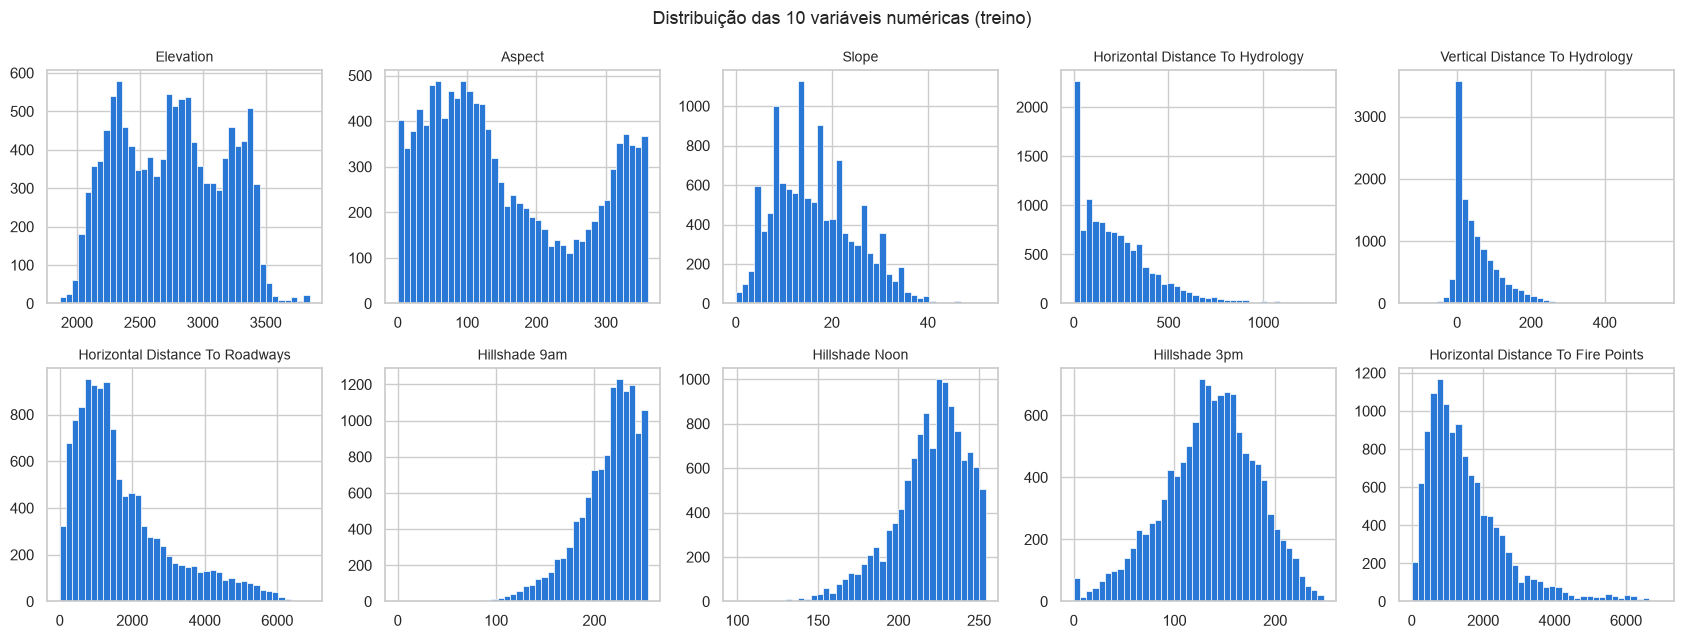

In [24]:
# Histograma de cada variável numérica, só com os dados de treino
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
for ax, col in zip(axes.flat, NUM_COLS):
    ax.hist(X_train[col], bins=40, color=CLASS_COLORS["Spruce/Fir"], edgecolor="white", linewidth=0.5)
    ax.set_title(col.replace("_", " "), fontsize=10)
    ax.set_ylabel("")
fig.suptitle("Distribuição das 10 variáveis numéricas (treino)", fontsize=13)
plt.tight_layout()
plt.show()

- **Elevação tem vários picos:** sinal de grupos em faixas de altitude diferentes.
- **Distâncias concentradas perto de zero**, com cauda longa.
- **`Aspect` sobe de novo perto de 360°:** as duas pontas são a mesma direção (norte).
- **`Hillshade_3pm` tem uma barra isolada em zero** (seção 4.4).

### 4.2 Variáveis numéricas por espécie

Este é o gráfico central da exploração.

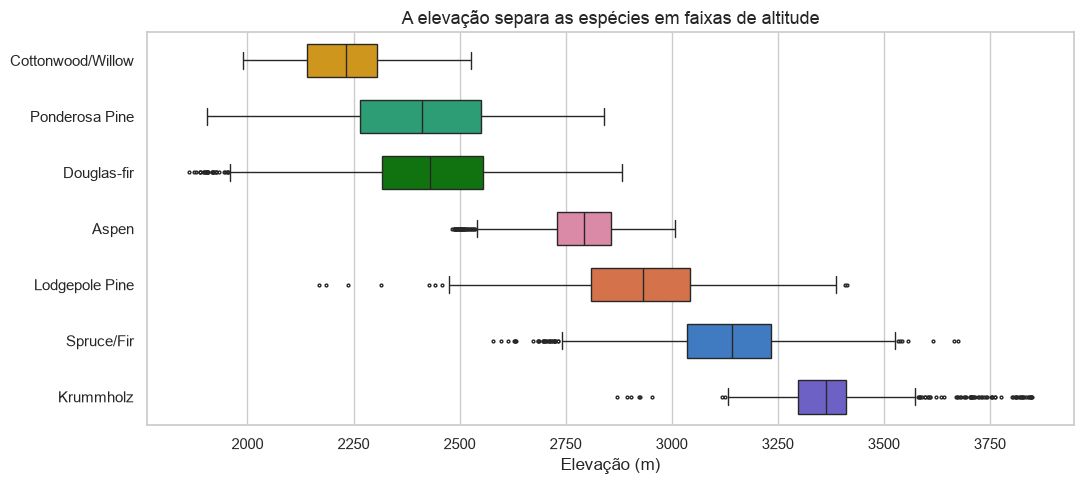

In [25]:
# Boxplot da elevação por espécie, ordenado pela mediana
ordem_elev = d_train.groupby("espécie")["Elevation"].median().sort_values().index

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(
    data=d_train, x="Elevation", y="espécie", hue="espécie", order=ordem_elev,
    palette=CLASS_COLORS, width=0.6, linewidth=1, fliersize=2, ax=ax,
)
ax.set_title("A elevação separa as espécies em faixas de altitude", fontsize=13)
ax.set_xlabel("Elevação (m)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [26]:
# Medianas por espécie, na mesma ordem do gráfico
d_train.groupby("espécie")["Elevation"].describe()[["min", "25%", "50%", "75%", "max"]].loc[ordem_elev]

,min,25%,50%,75%,max
espécie,,,,,
Cottonwood/Willow,1989.0,2140.75,2232.5,2306.00,2526.0
Ponderosa Pine,1905.0,2266.00,2411.0,2551.00,2840.0
Douglas-fir,1863.0,2317.00,2431.0,2556.00,2883.0
Aspen,2482.0,2729.75,2794.0,2856.00,3007.0
Lodgepole Pine,2169.0,2809.00,2932.0,3042.25,3413.0
Spruce/Fir,2579.0,3035.75,3143.0,3234.00,3675.0
Krummholz,2870.0,3297.75,3364.0,3411.00,3849.0


A elevação separa as espécies em faixas, do Cottonwood/Willow (~2.230 m) ao Krummholz (~3.360 m). Mas dois pares se sobrepõem:

- **Ponderosa Pine e Douglas-fir** (medianas de ~2.410 e ~2.430 m);
- **Spruce/Fir e Lodgepole Pine** (faixas vizinhas).

Esses devem ser os pares mais confundidos (confirmado na seção 7.2).

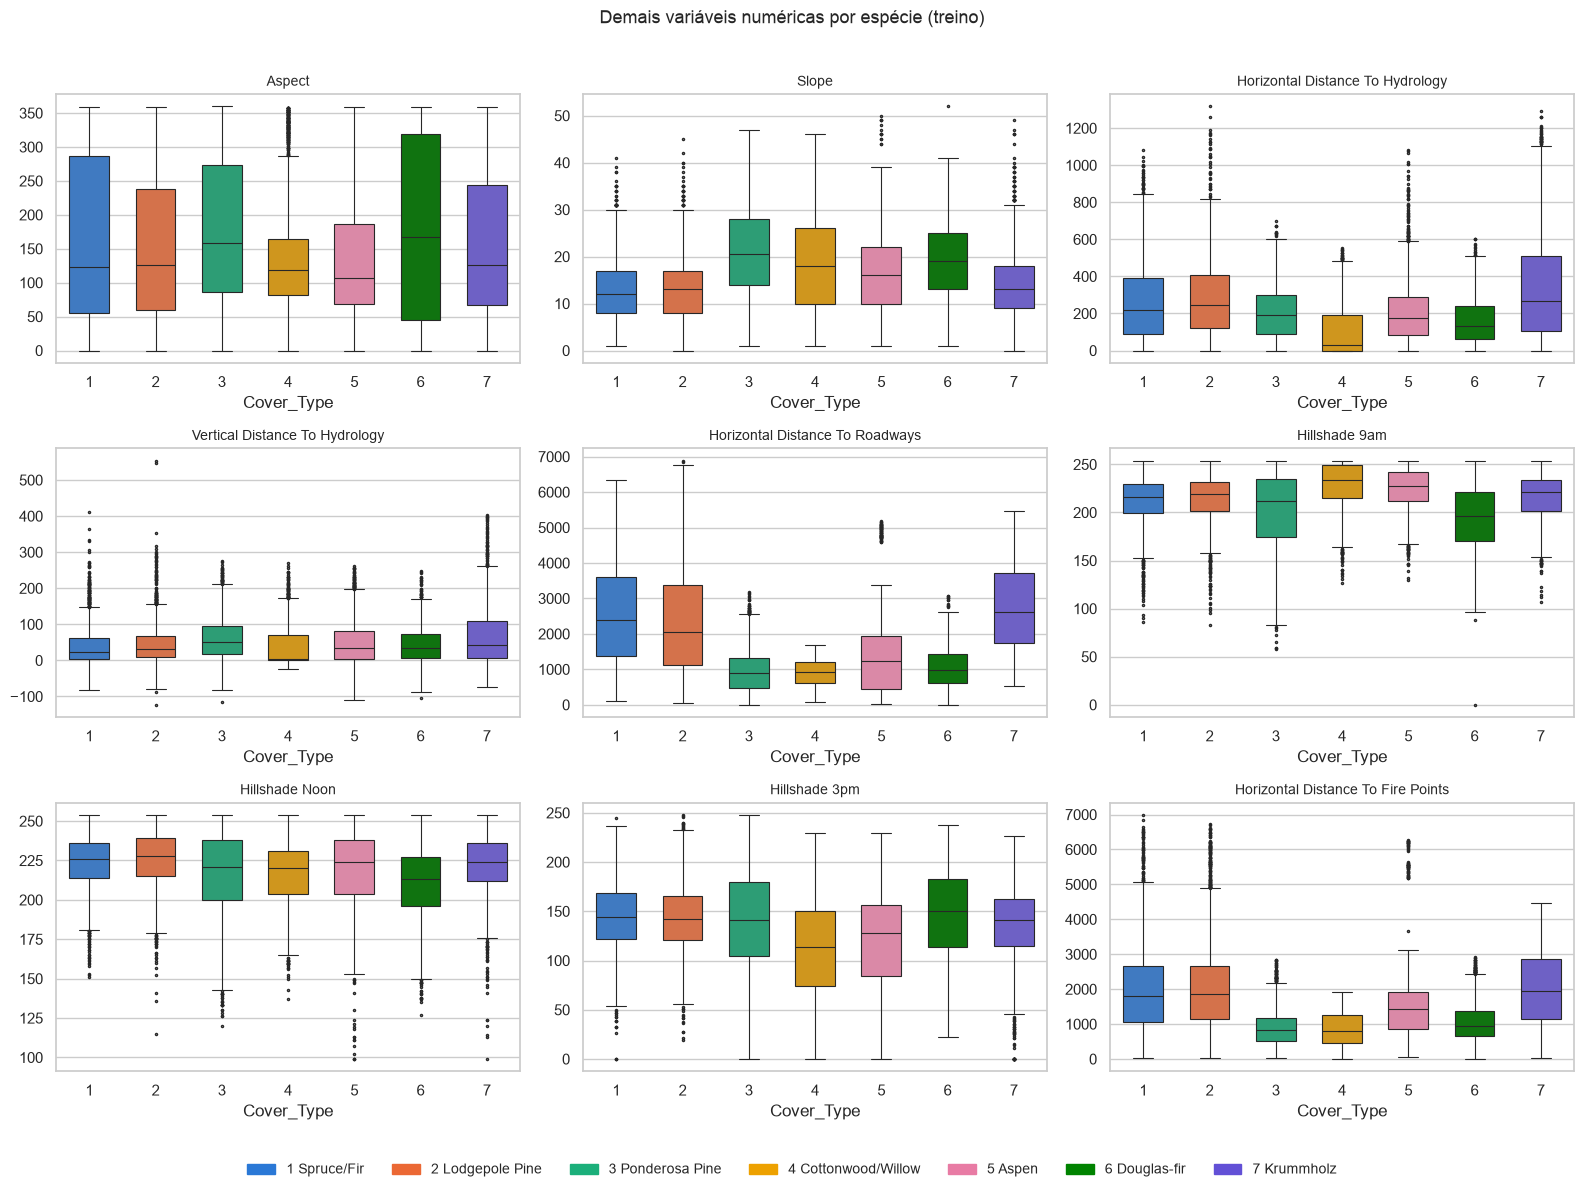

In [27]:
outras_num = [col for col in NUM_COLS if col != "Elevation"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, outras_num):
    sns.boxplot(
        data=d_train, x=TARGET, y=col, hue="espécie", palette=CLASS_COLORS,
        width=0.6, linewidth=0.8, fliersize=1.5, legend=False, ax=ax,
    )
    ax.set_title(col.replace("_", " "), fontsize=10)
    ax.set_xlabel("Cover_Type")
    ax.set_ylabel("")

# Legenda única com o nome de cada classe
handles = [plt.Rectangle((0, 0), 1, 1, color=cor) for cor in CLASS_COLORS.values()]
rotulos = [f"{k} {v}" for k, v in COVER_NAMES.items()]
fig.legend(handles, rotulos, loc="lower center", ncol=7, frameon=False, fontsize=10)
fig.suptitle("Demais variáveis numéricas por espécie (treino)", fontsize=13)
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

- **Distâncias até estradas e pontos de ignição** dividem as espécies nos mesmos dois grupos que a elevação: 1, 2 e 7 longe; 3, 4 e 6 perto.
- **Cottonwood/Willow fica muito perto da água** (mediana ~30 m), coerente com vegetação ribeirinha.
- **Inclinação e sombreamento** variam pouco entre espécies.

Os pares difíceis (3 e 6, 1 e 2) também se parecem aqui.

### 4.3 Correlação entre as variáveis numéricas

Procuro variáveis redundantes (correlação acima de 0,9).

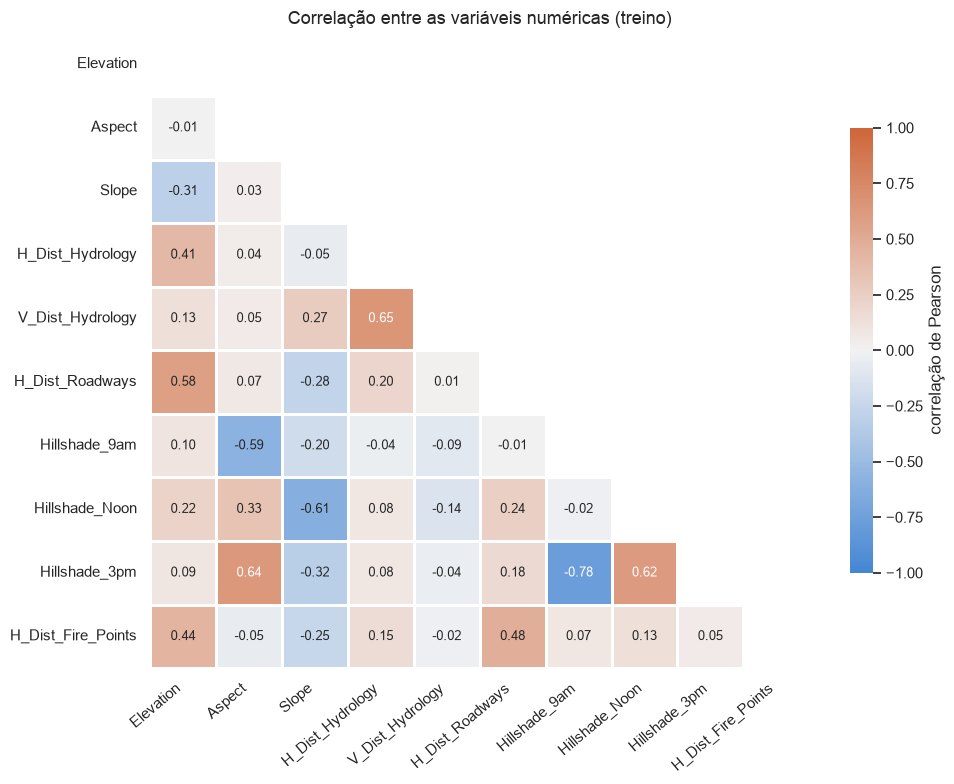

In [28]:
corr = X_train[NUM_COLS].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))  # mostra só o triângulo inferior

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, mask=mascara, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(250, 25, s=80, l=55, center="light", as_cmap=True),
    linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7, "label": "correlação de Pearson"},
    annot_kws={"size": 9}, ax=ax,
)
nomes_curtos = [col.replace("Horizontal_Distance_To_", "H_Dist_").replace("Vertical_Distance_To_", "V_Dist_") for col in NUM_COLS]
ax.set_xticklabels(nomes_curtos, rotation=40, ha="right")
ax.set_yticklabels(nomes_curtos, rotation=0)
ax.set_title("Correlação entre as variáveis numéricas (treino)", fontsize=13)
ax.grid(False)
plt.tight_layout()
plt.show()

In [29]:
# Pares com correlação absoluta acima de 0,5, do mais forte para o mais fraco
pares = corr.where(~mascara).stack()
pares[pares.abs() > 0.5].sort_values(key=abs, ascending=False).round(2).to_frame("correlação")

correlação
Hillshade_3pm                   Hillshade_9am                          -0.78
Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Hydrology        0.65
Hillshade_3pm                   Aspect                                  0.64
                                Hillshade_Noon                          0.62
Hillshade_Noon                  Slope                                  -0.61
Hillshade_9am                   Aspect                                 -0.59
Horizontal_Distance_To_Roadways Elevation                               0.58

O par mais forte é -0,78 (sombreamento às 9h e às 15h). Como nenhum passa de 0,9, mantenho todas. As correlações têm explicação física: o sombreamento depende de `Aspect` e `Slope`, e as distâncias horizontal e vertical até a água crescem juntas (0,65).

### 4.4 Outliers e valores suspeitos

**Zeros em `Hillshade_3pm`:** sombra real ou valor faltante? Comparo com o sombreamento das 9h.

Zeros em Hillshade_3pm no treino: 70 (0.58%)


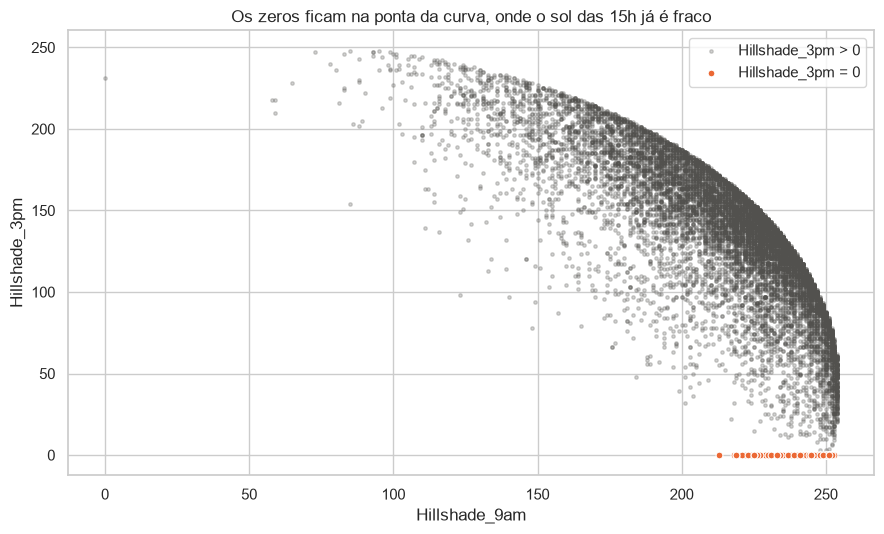

In [30]:
# Compara as linhas com Hillshade_3pm = 0 com o restante, no plano 9h x 15h
zeros_3pm = X_train["Hillshade_3pm"] == 0
print(f"Zeros em Hillshade_3pm no treino: {zeros_3pm.sum()} ({zeros_3pm.mean():.2%})")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X_train.loc[~zeros_3pm, "Hillshade_9am"], X_train.loc[~zeros_3pm, "Hillshade_3pm"],
           s=6, alpha=0.25, color=COR_NEUTRA, label="Hillshade_3pm > 0")
ax.scatter(X_train.loc[zeros_3pm, "Hillshade_9am"], X_train.loc[zeros_3pm, "Hillshade_3pm"],
           s=24, color=CLASS_COLORS["Lodgepole Pine"], edgecolor="white", linewidth=0.8,
           label="Hillshade_3pm = 0")
ax.set_xlabel("Hillshade_9am")
ax.set_ylabel("Hillshade_3pm")
ax.set_title("Os zeros ficam na ponta da curva, onde o sol das 15h já é fraco", fontsize=12)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

A maioria dos zeros fica onde o sol das 9h é forte e o das 15h já chega a quase zero: parecem sombra real. Alguns ficam abaixo da faixa e são suspeitos. Para quantificar, prevejo `Hillshade_3pm` a partir das outras variáveis de relevo.

In [31]:
cols_relevo = ["Hillshade_9am", "Hillshade_Noon", "Aspect", "Slope"]
regressor = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)

# Quão bem as outras variáveis de relevo explicam Hillshade_3pm (só linhas sem zero)
r2 = cross_val_score(regressor, X_train.loc[~zeros_3pm, cols_relevo],
                     X_train.loc[~zeros_3pm, "Hillshade_3pm"], cv=5, scoring="r2")
print(f"R² na validação cruzada: {r2.mean():.4f}")

# Valor previsto para as linhas em que Hillshade_3pm é zero
regressor.fit(X_train.loc[~zeros_3pm, cols_relevo], X_train.loc[~zeros_3pm, "Hillshade_3pm"])
previsto = pd.Series(regressor.predict(X_train.loc[zeros_3pm, cols_relevo]), index=X_train.index[zeros_3pm])
print("Previsão para os zeros (quantis):", previsto.quantile([0, 0.25, 0.5, 0.75, 1]).round(0).tolist())
print(f"Zeros com previsão abaixo de 30: {(previsto < 30).sum()} de {len(previsto)}")

R² na validação cruzada: 0.9996


Previsão para os zeros (quantis): [2.0, 6.0, 9.0, 25.0, 170.0]
Zeros com previsão abaixo de 30: 54 de 70


O relevo explica `Hillshade_3pm` quase perfeitamente (R² ≈ 0,9996). Em 54 dos 70 zeros a previsão é baixa (sombra real); 16 são provavelmente faltantes.

**Decisão:** mantenho os zeros. São 16 linhas (0,13%), numa variável em boa parte redundante.

In [32]:
# Valores negativos da distância vertical até a água, por espécie
negativos = (X_train["Vertical_Distance_To_Hydrology"] < 0).groupby(d_train["espécie"]).mean()
print(f"Linhas com distância vertical negativa no treino: {(X_train['Vertical_Distance_To_Hydrology'] < 0).sum()}")
(negativos * 100).round(1).to_frame("% de linhas com valor negativo")

Linhas com distância vertical negativa no treino: 929


,% de linhas com valor negativo
espécie,
Aspen,9.0
Cottonwood/Willow,2.4
Douglas-fir,6.7
Krummholz,9.1
Lodgepole Pine,8.7
Ponderosa Pine,5.6
Spruce/Fir,12.3


**Negativos em `Vertical_Distance_To_Hydrology`:** aparecem em todas as espécies (2% a 12%) e são válidos. Ficam como estão.

In [33]:
# Outliers pelo critério do IQR: abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR
q1, q3 = X_train[NUM_COLS].quantile(0.25), X_train[NUM_COLS].quantile(0.75)
iqr = q3 - q1
fora = (X_train[NUM_COLS] < q1 - 1.5 * iqr) | (X_train[NUM_COLS] > q3 + 1.5 * iqr)

pd.DataFrame({
    "outliers (IQR)": fora.sum(),
    "% do treino": (fora.mean() * 100).round(1),
}).sort_values("outliers (IQR)", ascending=False)

,outliers (IQR),% do treino
Horizontal_Distance_To_Roadways,653,5.4
Horizontal_Distance_To_Fire_Points,542,4.5
Horizontal_Distance_To_Hydrology,434,3.6
Vertical_Distance_To_Hydrology,431,3.6
Hillshade_9am,332,2.7
Hillshade_Noon,310,2.6
Hillshade_3pm,99,0.8
Slope,51,0.4
Elevation,0,0.0
Aspect,0,0.0


**Outliers pelo IQR:** 2,6% a 5,4% nas distâncias e sombreamentos. Não removo, porque:

1. são valores fisicamente plausíveis;
2. carregam informação (distâncias grandes são típicas de Spruce/Fir, Lodgepole Pine e Krummholz);
3. árvores são robustas a eles.

### 4.5 Área selvagem e tipo de solo por espécie

Mostro a porcentagem de cada espécie em cada categoria (comparável entre espécies, porque as classes são balanceadas).

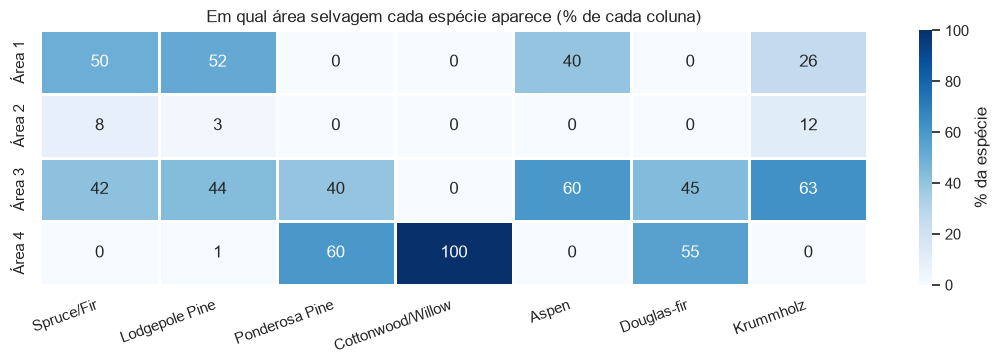

In [34]:
# Converte o one-hot de área selvagem em uma única coluna e calcula a % de cada espécie por área
area = X_train[WILD_COLS].idxmax(axis=1).str.replace("Wilderness_Area", "Área ")
tab_area = pd.crosstab(area, d_train["espécie"], normalize="columns")[list(COVER_NAMES.values())] * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(tab_area, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            linewidths=1, linecolor="white", cbar_kws={"label": "% da espécie"}, ax=ax)
ax.set_title("Em qual área selvagem cada espécie aparece (% de cada coluna)", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

- **Área 4** tem 100% do Cottonwood/Willow e a maior parte de Ponderosa Pine e Douglas-fir.
- **Áreas 1 e 2** não têm nenhuma dessas três espécies.

A área selvagem descarta espécies de forma eficaz, mas não separa os pares difíceis.

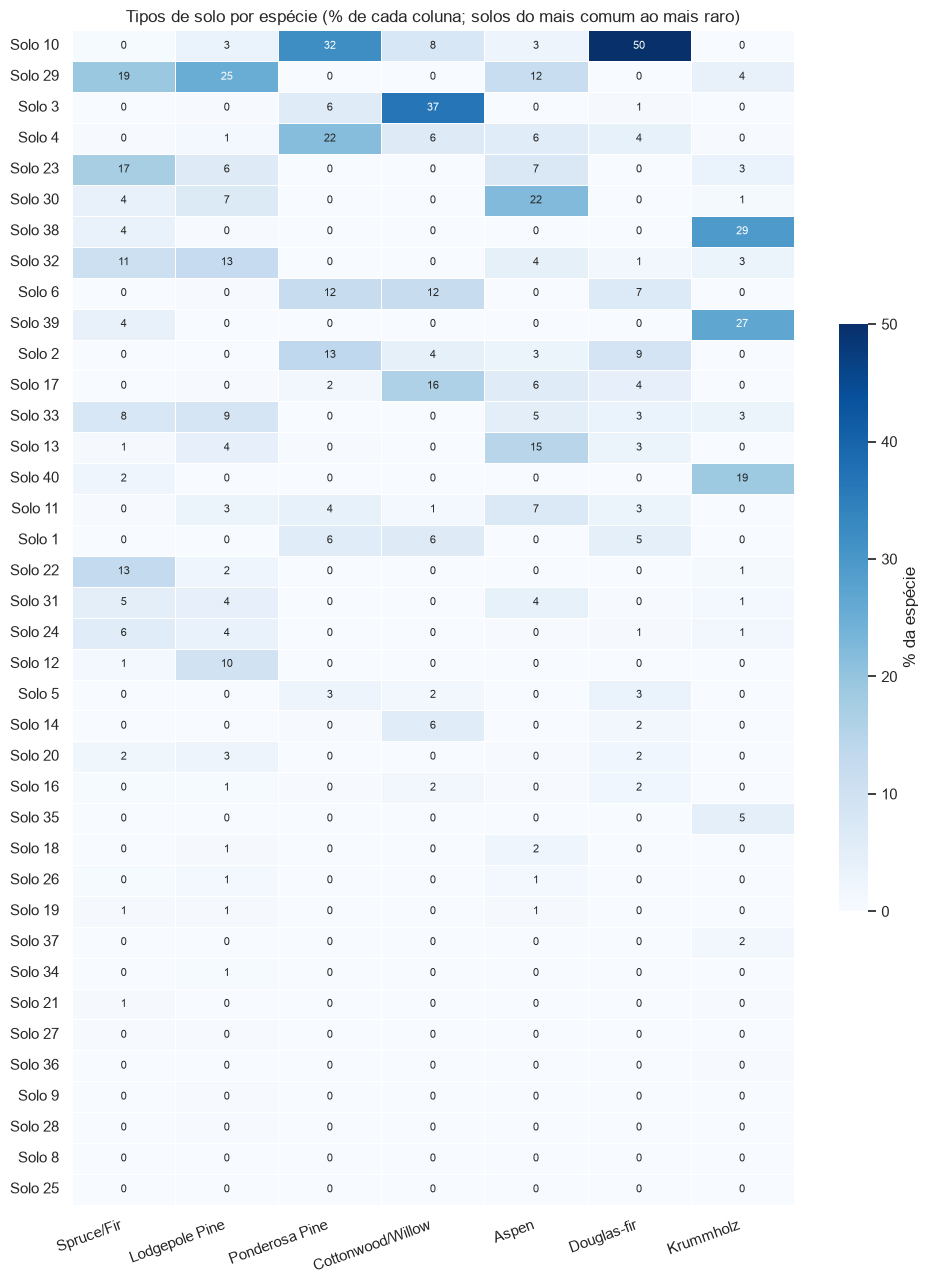

In [35]:
solo = X_train[[c for c in SOIL_COLS if c in X_train.columns]].idxmax(axis=1).str.replace("Soil_Type", "Solo ")
tab_solo = pd.crosstab(solo, d_train["espécie"], normalize="columns")[list(COVER_NAMES.values())] * 100
# Ordena os solos pelo número de amostras, do mais comum para o mais raro
tab_solo = tab_solo.loc[solo.value_counts().index]

fig, ax = plt.subplots(figsize=(10, 13))
sns.heatmap(tab_solo, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=50,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "% da espécie", "shrink": 0.5},
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Tipos de solo por espécie (% de cada coluna; solos do mais comum ao mais raro)", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

- **Solos 38 a 40:** quase só Krummholz. **Solo 3:** Cottonwood/Willow. **Solo 30:** Aspen.
- **Solo 10:** Douglas-fir (50%) mais que Ponderosa Pine (32%), o que ajuda um pouco no par 3 e 6.
- **Spruce/Fir e Lodgepole Pine** compartilham os solos 29 e 32; os solos 22, 23 e 12 ajudam a separá-los.

### 4.6 Distâncias até estradas e pontos de ignição: uma pista de localização

Testo a hipótese da seção 3.4: essas duas distâncias funcionariam como coordenadas geográficas?

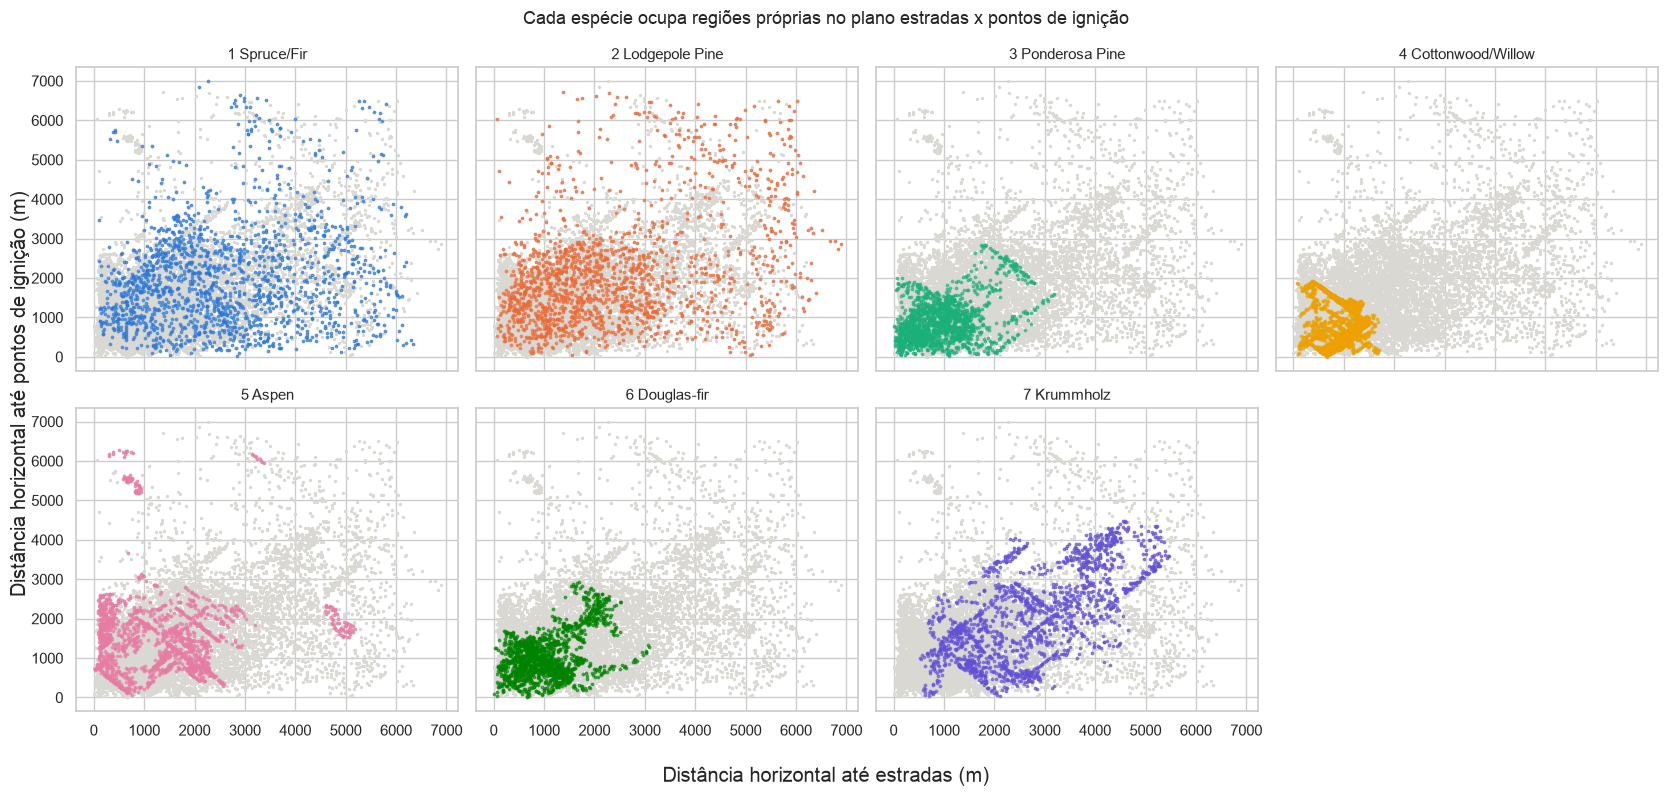

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)
x_col, y_col = "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points"

for ax, (classe, nome) in zip(axes.flat, COVER_NAMES.items()):
    ax.scatter(X_train[x_col], X_train[y_col], s=2, color="#d9d8d3", rasterized=True)
    da_classe = d_train[TARGET] == classe
    ax.scatter(X_train.loc[da_classe, x_col], X_train.loc[da_classe, y_col],
               s=3, alpha=0.6, color=CLASS_COLORS[nome], rasterized=True)
    ax.set_title(f"{classe} {nome}", fontsize=11)

axes.flat[-1].axis("off")
fig.supxlabel("Distância horizontal até estradas (m)")
fig.supylabel("Distância horizontal até pontos de ignição (m)")
fig.suptitle("Cada espécie ocupa regiões próprias no plano estradas x pontos de ignição", fontsize=13)
plt.tight_layout()
plt.show()

Sim, em parte. Os pontos formam **trilhas e aglomerados** (pontos vizinhos no terreno), e cada espécie ocupa os seus. Isso explica o KNN sem padronização e motiva as somas e diferenças de distâncias da seção 5.

## 5. Engenharia e seleção de features

Crio features a partir dos achados da seção 4 e meço o ganho de cada grupo com validação cruzada.

- **Sem vazamento:** as features são calculadas linha a linha, sem estatísticas do conjunto. Ficam dentro do `Pipeline` (`FunctionTransformer`) para serem aplicadas igualmente em todos os dados.
- **Comparação pareada:** uso os mesmos 5 folds e conto em quantos folds cada conjunto vence, além da média. Testo cinco modelos, porque uma feature útil para um modelo linear pode não servir para uma árvore.

### 5.1 Criação das features

| Grupo | Features | Justificativa |
|---|---|---|
| `aspect` | `Aspect_sin`, `Aspect_cos` | `Aspect` é circular: 1° e 359° são quase a mesma direção |
| `hidro` | `Dist_Hidro` = √(H² + V²) | Distância real até a água (H e V correlacionadas, seção 4.3) |
| `elev` | `Elev_Menos_VHidro` = `Elevation` − V | Altitude da água mais próxima: descreve o vale, não só o ponto |
| `dist` | 6 somas e diferenças entre distâncias (água, estradas, fogo) | Pistas de localização (seção 4.6); permitem cortes "diagonais" às árvores |

In [37]:
H_HIDRO = "Horizontal_Distance_To_Hydrology"
V_HIDRO = "Vertical_Distance_To_Hydrology"
ESTRADA = "Horizontal_Distance_To_Roadways"
FOGO = "Horizontal_Distance_To_Fire_Points"

# Nomes das features criadas, por grupo (usados na comparação da seção 5.2)
GRUPOS_FEATURES = {
    "aspect": ["Aspect_sin", "Aspect_cos"],
    "hidro": ["Dist_Hidro"],
    "elev": ["Elev_Menos_VHidro"],
    "dist": ["Hidro_Mais_Fogo", "Hidro_Menos_Fogo", "Hidro_Mais_Estrada",
             "Hidro_Menos_Estrada", "Fogo_Mais_Estrada", "Fogo_Menos_Estrada"],
}


def criar_features(X):
    """Acrescenta as features candidatas. Transformação linha a linha, sem parâmetros aprendidos."""
    X = X.copy()
    aspect_rad = np.deg2rad(X["Aspect"])
    X["Aspect_sin"] = np.sin(aspect_rad)
    X["Aspect_cos"] = np.cos(aspect_rad)

    X["Dist_Hidro"] = np.sqrt(X[H_HIDRO] ** 2 + X[V_HIDRO] ** 2)

    X["Elev_Menos_VHidro"] = X["Elevation"] - X[V_HIDRO]

    X["Hidro_Mais_Fogo"] = X[H_HIDRO] + X[FOGO]
    X["Hidro_Menos_Fogo"] = X[H_HIDRO] - X[FOGO]
    X["Hidro_Mais_Estrada"] = X[H_HIDRO] + X[ESTRADA]
    X["Hidro_Menos_Estrada"] = X[H_HIDRO] - X[ESTRADA]
    X["Fogo_Mais_Estrada"] = X[FOGO] + X[ESTRADA]
    X["Fogo_Menos_Estrada"] = X[FOGO] - X[ESTRADA]
    return X


TODAS_NOVAS = [col for grupo in GRUPOS_FEATURES.values() for col in grupo]
criar_features(X_train)[TODAS_NOVAS].head()

,Aspect_sin,Aspect_cos,Dist_Hidro,Elev_Menos_VHidro,Hidro_Mais_Fogo,Hidro_Menos_Fogo,Hidro_Mais_Estrada,Hidro_Menos_Estrada,Fogo_Mais_Estrada,Fogo_Menos_Estrada
14128,0.484810,-0.874620,421.730957,2751,1213,-461,2304,-1552,2765,-1091
4425,-0.874620,0.484810,90.669730,2880,1550,-1370,1760,-1580,3130,-210
909,-0.913545,0.406737,217.018432,2907,1960,-1528,5291,-4859,6819,-3331
5123,0.587785,-0.809017,122.376468,2803,1301,-1061,2375,-2135,3436,-1074
10901,-0.406737,0.913545,32.310989,2547,554,-494,2036,-1976,2530,-1482


In [38]:
# Conferência do seno/cosseno: 1° e 359° ficam próximos; 0° e 360° ficam idênticos
teste_aspect = pd.DataFrame({"Aspect": [0, 1, 90, 180, 359, 360]})
teste_aspect["sin"] = np.sin(np.deg2rad(teste_aspect["Aspect"])).round(3)
teste_aspect["cos"] = np.cos(np.deg2rad(teste_aspect["Aspect"])).round(3)
teste_aspect

,Aspect,sin,cos
0,0,0.000,1.0
1,1,0.017,1.0
2,90,1.000,0.0
3,180,0.000,-1.0
4,359,-0.017,1.0
5,360,-0.000,1.0


Conferido: 0° e 360° viram o mesmo ponto. A função abaixo monta o pipeline completo; para comparar conjuntos de features, basta trocar a lista `num_cols`.

In [39]:
def build_pipeline(modelo, num_cols, bin_cols=BIN_COLS, padronizar=True):
    """Pipeline completo: features novas -> imputação/padronização -> modelo."""
    return Pipeline([
        ("features", FunctionTransformer(criar_features)),
        ("prep", build_preprocessor(num_cols, bin_cols, padronizar=padronizar)),
        ("model", modelo),
    ])


def acuracia_por_fold(pipeline, X, y):
    """Acurácia em cada um dos 5 folds de CV (sempre os mesmos folds)."""
    return cross_validate(pipeline, X, y, cv=CV, scoring="accuracy", n_jobs=-1)["test_score"]

### 5.2 Medição do ganho com validação cruzada

Comparo o conjunto original com "todas as features" e com "todas menos um grupo". Retirar um grupo de cada vez mostra sua contribuição quando os outros já estão presentes. A última linha testa substituir `Aspect` pelo seno e cosseno.

In [40]:
CONJUNTOS = {
    "Original": NUM_COLS,
    "Todas": NUM_COLS + TODAS_NOVAS,
    **{
        f"Todas sem '{grupo}'": NUM_COLS + [c for c in TODAS_NOVAS if c not in cols]
        for grupo, cols in GRUPOS_FEATURES.items()
    },
    "Todas, Aspect substituído": [c for c in NUM_COLS if c != "Aspect"] + TODAS_NOVAS,
}

MODELOS_TESTE = {
    "Regressão logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

# Acurácia por fold de cada combinação conjunto x modelo (leva alguns minutos)
scores_fe = {
    (conjunto, nome): acuracia_por_fold(build_pipeline(modelo, cols), X_train, y_train)
    for conjunto, cols in CONJUNTOS.items()
    for nome, modelo in MODELOS_TESTE.items()
}

In [41]:
def resumo_ganho(scores, referencia="Original"):
    """Tabelas de acurácia média, ganho médio (pontos percentuais) e folds com melhora."""
    conjuntos = list(dict.fromkeys(c for c, _ in scores))
    modelos = list(dict.fromkeys(m for _, m in scores))
    acc = pd.DataFrame({m: [scores[(c, m)].mean() for c in conjuntos] for m in modelos}, index=conjuntos)
    ganho = pd.DataFrame({m: [(scores[(c, m)] - scores[(referencia, m)]).mean() * 100 for c in conjuntos]
                          for m in modelos}, index=conjuntos)
    folds = pd.DataFrame({m: [int((scores[(c, m)] > scores[(referencia, m)]).sum()) for c in conjuntos]
                          for m in modelos}, index=conjuntos)
    return acc, ganho, folds


acc_fe, ganho_fe, folds_fe = resumo_ganho(scores_fe)
(acc_fe * 100).round(2)

,Regressão logística,KNN,Random Forest,Extra Trees,HistGradientBoosting
Original,70.49,77.36,85.39,85.51,85.03
Todas,71.51,79.01,87.81,88.62,87.42
Todas sem 'aspect',70.68,79.98,88.08,89.07,87.29
Todas sem 'hidro',71.46,79.45,87.83,88.69,87.30
Todas sem 'elev',71.35,78.17,87.39,87.90,86.83
Todas sem 'dist',71.48,77.38,85.61,85.73,85.86
"Todas, Aspect substituído",71.31,79.94,88.02,88.99,87.26


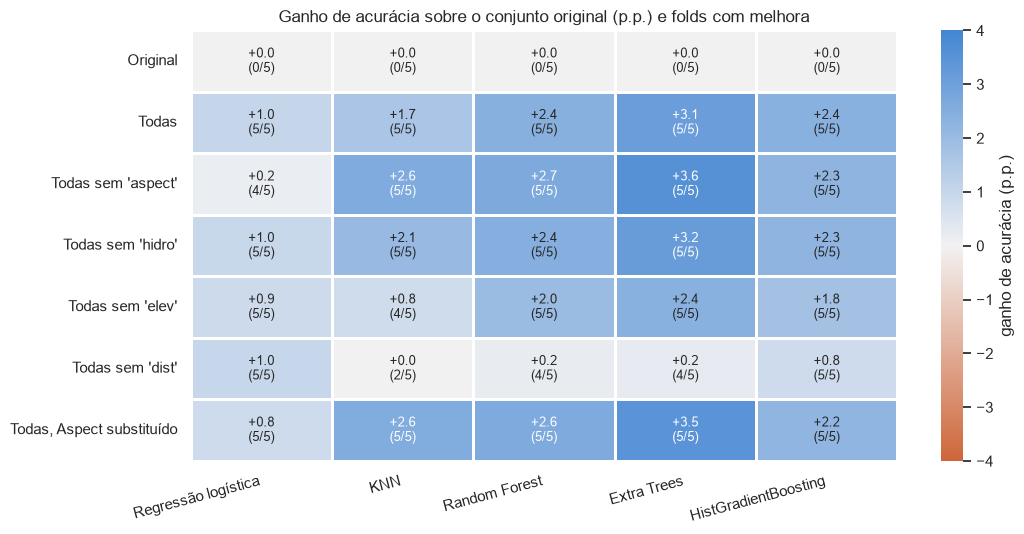

In [42]:
# Ganho em relação ao conjunto original, com o número de folds (de 5) em que houve melhora
anotacao = ganho_fe.map(lambda v: f"{v:+.1f}") + "\n(" + folds_fe.astype(str) + "/5)"

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(ganho_fe, annot=anotacao, fmt="", center=0, vmin=-4, vmax=4,
            cmap=sns.diverging_palette(25, 250, s=80, l=55, center="light", as_cmap=True),
            linewidths=1, linecolor="white", cbar_kws={"label": "ganho de acurácia (p.p.)"},
            annot_kws={"size": 9}, ax=ax)
ax.set_title("Ganho de acurácia sobre o conjunto original (p.p.) e folds com melhora", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Cada célula mostra o ganho em pontos percentuais (p.p.) e, entre parênteses, em quantos folds houve melhora.

- **`dist` é o grupo decisivo:** sem ele, a maior parte do ganho some. Confirma a seção 4.6.
- **`elev` ajuda todos os modelos** (0,2 a 0,8 p.p.).
- **`aspect` só ajuda a regressão logística.** Nas árvores e no KNN, somado ao `Aspect` original, atrapalha. **Substituir** `Aspect` resolve.
- **`hidro` não muda nada** (menos de 0,5 p.p.).

### 5.3 Seleção do conjunto final de features

- **Mantenho** `dist` e `elev`.
- **Substituo** `Aspect` por seno e cosseno.
- **Descarto** `Dist_Hidro` (sem ganho; dimensões inúteis prejudicam o KNN).
- **Mantenho todas as binárias** (árvores ignoram as inúteis; vários solos são quase exclusivos de uma espécie).

Resultado: 18 numéricas e 42 binárias (60 features).

In [43]:
# Conjunto final: Aspect substituído por seno/cosseno, mais elevação da água e somas/diferenças de distâncias
NUM_COLS_FE = (
    [c for c in NUM_COLS if c != "Aspect"]
    + GRUPOS_FEATURES["aspect"] + GRUPOS_FEATURES["elev"] + GRUPOS_FEATURES["dist"]
)
print(f"Conjunto final: {len(NUM_COLS_FE)} numéricas + {len(BIN_COLS)} binárias = {len(NUM_COLS_FE) + len(BIN_COLS)} features")

scores_final = {
    (conjunto, nome): (scores_fe[("Original", nome)] if conjunto == "Original"
                       else acuracia_por_fold(build_pipeline(modelo, NUM_COLS_FE), X_train, y_train))
    for conjunto in ["Original", "Selecionado"]
    for nome, modelo in MODELOS_TESTE.items()
}
acc_sel, ganho_sel, folds_sel = resumo_ganho(scores_final)

pd.DataFrame({
    "acurácia original (%)": (acc_sel.loc["Original"] * 100).round(2),
    "acurácia selecionado (%)": (acc_sel.loc["Selecionado"] * 100).round(2),
    "ganho (p.p.)": ganho_sel.loc["Selecionado"].round(2),
    "folds com melhora": folds_sel.loc["Selecionado"].astype(str) + "/5",
})

Conjunto final: 18 numéricas + 42 binárias = 60 features


,acurácia original (%),acurácia selecionado (%),ganho (p.p.),folds com melhora
Regressão logística,70.49,71.37,0.88,5/5
KNN,77.36,80.37,3.02,5/5
Random Forest,85.39,88.45,3.06,5/5
Extra Trees,85.51,89.16,3.65,5/5
HistGradientBoosting,85.03,87.39,2.36,5/5


**O conjunto final melhora os cinco modelos em todos os folds**, de +0,9 p.p. (regressão logística) a +3,7 p.p. (Extra Trees). Como escolhi entre várias alternativas nos mesmos folds, a estimativa é um pouco otimista; o teste guardado (seção 7) dá a medida sem viés.

Abaixo, a informação mútua de cada feature com a espécie (mede dependência não linear, mas avalia cada feature isoladamente).

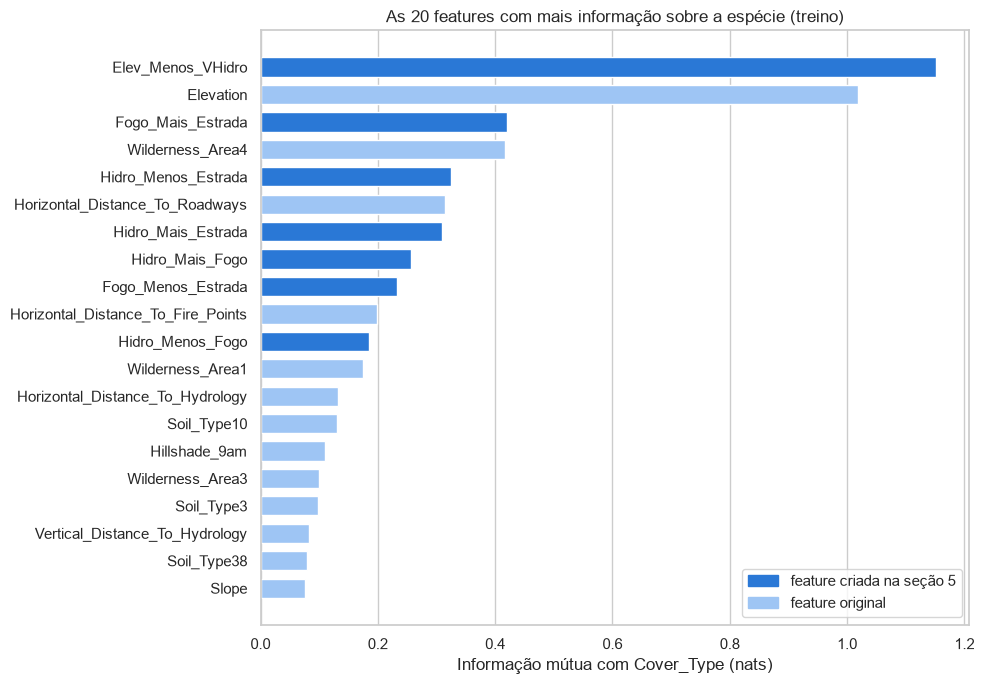

In [44]:
X_train_fe = criar_features(X_train)[NUM_COLS_FE + BIN_COLS]
info_mutua = pd.Series(
    mutual_info_classif(X_train_fe, y_train, discrete_features=[c in BIN_COLS for c in X_train_fe.columns],
                        random_state=RANDOM_STATE),
    index=X_train_fe.columns,
).sort_values(ascending=False)

top = info_mutua.head(20).iloc[::-1]
cores = [CLASS_COLORS["Spruce/Fir"] if c in TODAS_NOVAS else "#9ec5f4" for c in top.index]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index, top.values, color=cores, height=0.7)
ax.set_xlabel("Informação mútua com Cover_Type (nats)")
ax.set_title("As 20 features com mais informação sobre a espécie (treino)", fontsize=12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS["Spruce/Fir"]),
                   plt.Rectangle((0, 0), 1, 1, color="#9ec5f4")],
          labels=["feature criada na seção 5", "feature original"], loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

A melhor feature é uma das criadas: `Elev_Menos_VHidro` supera a própria elevação. Várias somas e diferenças de distâncias também ficam no topo, acima das distâncias originais.

## 6. Modelagem, comparação e validação cruzada

Comparo seis modelos com o mesmo pipeline e os mesmos 5 folds, para que as diferenças venham só do modelo. Métricas: acurácia (principal), precisão, recall e F1 macro (todas as classes com o mesmo peso) e AUC-ROC um-contra-todos (qualidade das probabilidades). Reporto média e desvio padrão nos folds.

### 6.1 Modelos escolhidos

| Modelo | Ideia | Por que incluí |
|---|---|---|
| `DummyClassifier` | Sempre prevê a mesma classe | Baseline (14,3%) |
| Regressão logística | Fronteira linear | Modelo mais simples e interpretável |
| KNN | Voto dos k vizinhos mais próximos | Vizinhos parecem ter a mesma espécie (seção 4.6) |
| Random Forest | Média de árvores em amostras bootstrap | Captura não linearidades; robusto |
| Extra Trees | Como o Random Forest, com cortes sorteados e sem bootstrap | Menor variância |
| `HistGradientBoosting` | Árvores em sequência, cada uma corrigindo a anterior | Boosting, forte em dados tabulares |

Todos usam hiperparâmetros padrão; ajusto só o melhor modelo (seção 6.4).

In [45]:
MODELOS = {
    "Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

METRICAS = {
    "acurácia": "accuracy",
    # zero_division=0: o Dummy nunca prevê 6 das 7 classes, e a precisão dessas classes fica indefinida
    "precisão macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall macro": "recall_macro",
    "F1 macro": "f1_macro",
    "AUC-ROC (OvR)": "roc_auc_ovr",
}

### 6.2 Comparação com validação cruzada

In [46]:
resultados_cv = {}
for nome, modelo in MODELOS.items():
    resultados_cv[nome] = cross_validate(
        build_pipeline(modelo, NUM_COLS_FE), X_train, y_train,
        cv=CV, scoring=METRICAS, n_jobs=-1,
    )

# Tabela com média ± desvio padrão de cada métrica nos 5 folds
tabela_cv = pd.DataFrame({
    nome: {
        **{m: f"{res[f'test_{m}'].mean():.4f} ± {res[f'test_{m}'].std():.4f}" for m in METRICAS},
        "treino (s/fold)": round(res["fit_time"].mean(), 1),
    }
    for nome, res in resultados_cv.items()
}).T
tabela_cv.sort_values("acurácia", ascending=False)

,acurácia,precisão macro,recall macro,F1 macro,AUC-ROC (OvR),treino (s/fold)
Extra Trees,0.8916 ± 0.0050,0.8901 ± 0.0049,0.8916 ± 0.0050,0.8903 ± 0.0048,0.9891 ± 0.0008,0.6
Random Forest,0.8845 ± 0.0028,0.8826 ± 0.0027,0.8845 ± 0.0027,0.8827 ± 0.0028,0.9879 ± 0.0005,1.0
HistGradientBoosting,0.8739 ± 0.0070,0.8715 ± 0.0070,0.8739 ± 0.0070,0.8720 ± 0.0069,0.9862 ± 0.0010,3.5
KNN,0.8037 ± 0.0058,0.7992 ± 0.0063,0.8037 ± 0.0057,0.7989 ± 0.0063,0.9590 ± 0.0020,0.0
Regressão logística,0.7137 ± 0.0089,0.7105 ± 0.0094,0.7137 ± 0.0089,0.7109 ± 0.0092,0.9519 ± 0.0011,0.3
Dummy (baseline),0.1426 ± 0.0000,0.0204 ± 0.0000,0.1429 ± 0.0000,0.0357 ± 0.0000,0.5000 ± 0.0000,0.0


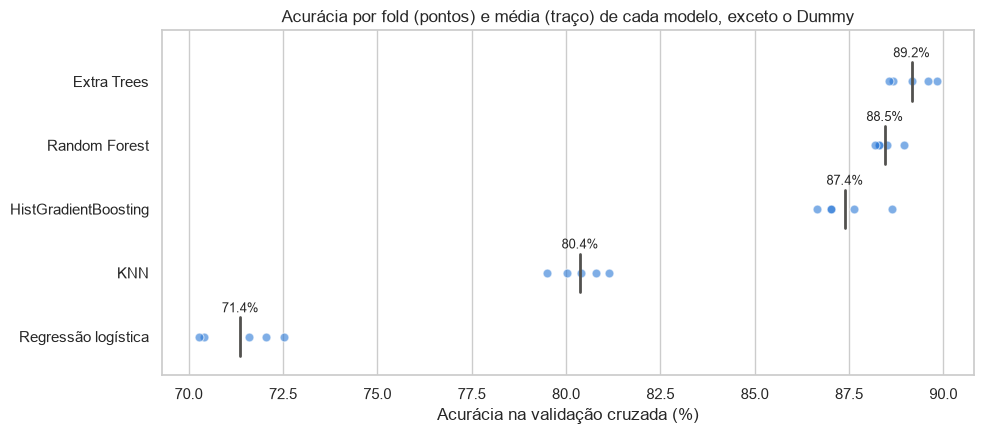

In [47]:
# Acurácia de cada fold, para visualizar a dispersão entre folds
acc_folds = pd.DataFrame({nome: res["test_acurácia"] for nome, res in resultados_cv.items()})
# O Dummy (14,3%) fica fora do gráfico para não achatar a escala; está na tabela acima
ordem = acc_folds.drop(columns="Dummy (baseline)").mean().sort_values().index

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, nome in enumerate(ordem):
    ax.scatter(acc_folds[nome] * 100, [i] * len(acc_folds), s=40, color=CLASS_COLORS["Spruce/Fir"],
               alpha=0.6, edgecolor="white", linewidth=0.8, zorder=3)
    ax.plot([acc_folds[nome].mean() * 100] * 2, [i - 0.3, i + 0.3], color=COR_NEUTRA, linewidth=2, zorder=4)
    ax.text(acc_folds[nome].mean() * 100, i + 0.38, f"{acc_folds[nome].mean():.1%}", ha="center", fontsize=9)
ax.set_yticks(range(len(ordem)))
ax.set_yticklabels(ordem)
ax.set_ylim(-0.6, len(ordem) - 0.2)
ax.set_xlabel("Acurácia na validação cruzada (%)")
ax.set_title("Acurácia por fold (pontos) e média (traço) de cada modelo, exceto o Dummy", fontsize=12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [48]:
# Comparação pareada entre os três melhores: em quantos folds um supera o outro
pares_modelos = [("Extra Trees", "Random Forest"), ("Extra Trees", "HistGradientBoosting"),
                 ("Random Forest", "HistGradientBoosting")]
pd.DataFrame([
    {
        "comparação": f"{a} x {b}",
        "diferença média (p.p.)": round((acc_folds[a] - acc_folds[b]).mean() * 100, 2),
        f"folds em que o primeiro vence": f"{int((acc_folds[a] > acc_folds[b]).sum())}/5",
    }
    for a, b in pares_modelos
]).set_index("comparação")

,diferença média (p.p.),folds em que o primeiro vence
comparação,,
Extra Trees x Random Forest,0.71,5/5
Extra Trees x HistGradientBoosting,1.77,5/5
Random Forest x HistGradientBoosting,1.06,5/5


- **Extra Trees é o melhor em todas as métricas** (89,2%) e vence Random Forest e HistGradientBoosting em todos os folds.
- **Regressão logística fica em ~71%:** as fronteiras entre espécies não são lineares (trilhas e aglomerados da seção 4.6).
- **KNN fica em ~80%:** captura a estrutura local, mas dá o mesmo peso a todas as 60 features.
- **Precisão, recall e F1 acompanham a acurácia**, como esperado com classes balanceadas.

O Extra Trees provavelmente vence o Random Forest porque cada árvore usa todo o treino (sem bootstrap): aqui, pontos vizinhos no terreno trazem muita informação, e deixar parte deles de fora custa caro.

### 6.3 KNN: a padronização como hiperparâmetro

Retomo a dúvida da seção 3.4, agora com as features novas, testando padronização (sim/não), número de vizinhos e ponderação dos votos.

In [49]:
# Busca em grade no KNN: padronização (sim/não), número de vizinhos e forma de ponderar os votos
grade_knn = {
    "prep__num__scaler": [StandardScaler(), "passthrough"],
    "model__n_neighbors": [1, 3, 5, 7, 9, 15],
    "model__weights": ["uniform", "distance"],
}
busca_knn = GridSearchCV(build_pipeline(KNeighborsClassifier(), NUM_COLS_FE), grade_knn,
                         cv=CV, scoring="accuracy", n_jobs=-1)
busca_knn.fit(X_train, y_train)

res_knn = pd.DataFrame(busca_knn.cv_results_)
res_knn["padronização"] = res_knn["param_prep__num__scaler"].map(lambda s: "não" if s == "passthrough" else "sim")
(res_knn.pivot_table(index="param_model__n_neighbors", columns=["padronização", "param_model__weights"],
                     values="mean_test_score") * 100).round(2).rename_axis(index="k")

padronização              não              sim        
param_model__weights distance uniform distance uniform
k                                                     
1                       79.30   79.30    82.71   82.71
3                       77.74   76.30    82.29   81.24
5                       77.17   75.15    81.85   80.37
7                       76.25   73.34    81.23   79.46
9                       75.83   72.20    80.48   78.36
15                      74.09   69.90    78.81   76.31

In [50]:
# Melhor combinação de hiperparâmetros do KNN e sua acurácia média nos 5 folds
print("Melhor combinação:", busca_knn.best_params_)
print(f"Acurácia na validação cruzada: {busca_knn.best_score_:.4f}")

Melhor combinação: {'model__n_neighbors': 1, 'model__weights': 'uniform', 'prep__num__scaler': StandardScaler()}
Acurácia na validação cruzada: 0.8271


**Com as features novas, a padronização vence para todo k** (de 3 a 6 p.p.). As somas e diferenças de distâncias trazem a informação de localização que antes vinha da escala bruta. O melhor é k = 1 (82,7%), coerente com as trilhas de pontos vizinhos. Mesmo assim, o KNN fica ~6 p.p. atrás do Extra Trees.

### 6.4 Ajuste de hiperparâmetros do Extra Trees

Uso `RandomizedSearchCV` com 40 combinações sorteadas, mais eficiente que uma grade completa com seis hiperparâmetros: número de árvores, fração de features por corte, profundidade máxima, mínimos de linhas por divisão e por folha, e uso de bootstrap. Leva cerca de 2 minutos.

In [51]:
espaco_et = {
    "model__n_estimators": randint(100, 600),
    "model__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, None],
    "model__max_depth": [None, 20, 30, 40],
    "model__min_samples_split": randint(2, 8),
    "model__min_samples_leaf": randint(1, 5),
    "model__bootstrap": [False, True],
}
busca_et = RandomizedSearchCV(
    # n_jobs=1 no modelo: o paralelismo fica na busca (um candidato por núcleo), sem paralelismo aninhado
    build_pipeline(ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1), NUM_COLS_FE),
    espaco_et, n_iter=40, cv=CV, scoring="accuracy", random_state=RANDOM_STATE, n_jobs=-1,
)
busca_et.fit(X_train, y_train)

# As 10 melhores combinações
res_et = pd.DataFrame(busca_et.cv_results_).sort_values("rank_test_score")
colunas_param = [c for c in res_et.columns if c.startswith("param_")]
top_et = res_et[colunas_param + ["mean_test_score", "std_test_score"]].head(10)
top_et.columns = [c.replace("param_model__", "") for c in top_et.columns]
top_et.round(4)

,bootstrap,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,mean_test_score,std_test_score
31,False,None,0.5,1,4,342,0.8952,0.0034
9,False,30,0.7,1,3,487,0.8949,0.0033
38,False,None,None,1,2,406,0.8946,0.0036
20,False,None,sqrt,1,2,443,0.8934,0.0040
10,False,40,None,2,3,364,0.8893,0.0039
26,False,None,0.3,1,7,230,0.8882,0.0028
5,True,None,0.5,1,2,574,0.8874,0.0034
19,True,40,0.5,1,2,256,0.8868,0.0038
36,False,None,0.3,2,2,215,0.8860,0.0038
12,True,30,0.5,1,4,305,0.8829,0.0031


In [52]:
# Comparação pareada: Extra Trees padrão x ajustado, nos mesmos 5 folds
acc_et_ajustado = np.array([res_et.loc[busca_et.best_index_, f"split{i}_test_score"] for i in range(5)])
acc_et_padrao = acc_folds["Extra Trees"].values

print("Melhores hiperparâmetros:", {k.replace("model__", ""): v for k, v in busca_et.best_params_.items()})
print(f"Extra Trees padrão:   {acc_et_padrao.mean():.4f} ± {acc_et_padrao.std():.4f}")
print(f"Extra Trees ajustado: {acc_et_ajustado.mean():.4f} ± {acc_et_ajustado.std():.4f}")
print(f"Ganho: {(acc_et_ajustado - acc_et_padrao).mean() * 100:+.2f} p.p., "
      f"melhor em {(acc_et_ajustado > acc_et_padrao).sum()}/5 folds")

Melhores hiperparâmetros: {'bootstrap': False, 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 342}
Extra Trees padrão:   0.8916 ± 0.0050
Extra Trees ajustado: 0.8952 ± 0.0034
Ganho: +0.36 p.p., melhor em 4/5 folds


- **Ganho pequeno (+0,4 p.p.):** os valores padrão já estavam perto do ótimo.
- **O que importa:** árvores completas (`min_samples_leaf=1`, sem limite de profundidade) e sem bootstrap. As fronteiras são muito fragmentadas e pedem regras locais; a média de centenas de árvores controla o sobreajuste.
- **`max_features` quase não importa:** as quatro melhores usam valores bem diferentes.

Como escolhi a melhor de 40 nos mesmos folds, os 89,5% são um pouco otimistas. O teste guardado resolve isso (seção 7).

### 6.5 Modelo final

**Extra Trees ajustado**, dentro do pipeline completo: melhor desempenho, treino rápido e resultado pouco sensível a hiperparâmetros. O `RandomizedSearchCV` já o retreinou com todos os 80% de treino.

In [53]:
modelo_final = busca_et.best_estimator_
# Volta a usar todos os núcleos na previsão (o teste do Kaggle tem 565 mil linhas)
modelo_final.set_params(model__n_jobs=-1)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](7,)","[1,2,3,...,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](52,)","['Elevation','Aspect','Slope',...,'Soil_Type38','Soil_Type39', 'Soil_Type40']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,52
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function cri...t 0x117a9bd80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


## 7. Avaliação dos resultados

Uso agora, **uma única vez**, os 20% de teste guardados desde a seção 3.3. Nada visto aqui volta para alterar o modelo.

### 7.1 Desempenho geral no teste guardado

In [54]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)

metricas_teste = {
    "acurácia": accuracy_score(y_test, y_pred),
    "precisão macro": precision_score(y_test, y_pred, average="macro"),
    "recall macro": recall_score(y_test, y_pred, average="macro"),
    "F1 macro": f1_score(y_test, y_pred, average="macro"),
    "AUC-ROC (OvR)": roc_auc_score(y_test, y_proba, multi_class="ovr"),
}

# Comparação com a estimativa da validação cruzada (seção 6.4), nos mesmos 80% de treino
cv_ajustado = {"acurácia": busca_et.best_score_}
pd.DataFrame({
    "teste guardado": metricas_teste,
    "validação cruzada (seção 6)": {**{m: resultados_cv["Extra Trees"][f"test_{m}"].mean() for m in METRICAS}, **cv_ajustado},
}).round(4)

,teste guardado,validação cruzada (seção 6)
acurácia,0.8988,0.8952
precisão macro,0.8969,0.8901
recall macro,0.8988,0.8916
F1 macro,0.8972,0.8903
AUC-ROC (OvR),0.9895,0.9891


In [55]:
# Intervalo de confiança aproximado (95%) da acurácia, tratando cada linha como uma tentativa independente
acc = metricas_teste["acurácia"]
erro_padrao = np.sqrt(acc * (1 - acc) / len(y_test))
print(f"Acurácia no teste: {acc:.2%} (IC 95%: {acc - 1.96 * erro_padrao:.2%} a {acc + 1.96 * erro_padrao:.2%})")

Acurácia no teste: 89.88% (IC 95%: 88.81% a 90.96%)


**Resultado: 89,9% de acurácia no teste guardado** (IC 95%: 88,8% a 91,0%), em linha com a validação cruzada (89,5%). Isso indica que não houve sobreajuste às escolhas nem vazamento de dados. O gráfico abaixo resume o caminho do baseline até aqui.

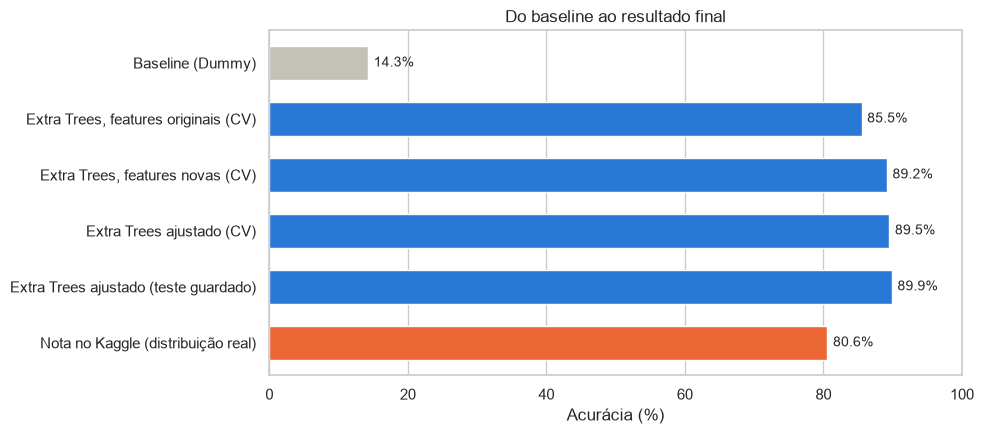

In [56]:
# Do baseline ao resultado final: acurácia em cada etapa do trabalho
etapas = pd.Series({
    "Baseline (Dummy)": resultados_cv["Dummy (baseline)"]["test_acurácia"].mean(),
    "Extra Trees, features originais (CV)": acc_fe.loc["Original", "Extra Trees"],
    "Extra Trees, features novas (CV)": resultados_cv["Extra Trees"]["test_acurácia"].mean(),
    "Extra Trees ajustado (CV)": busca_et.best_score_,
    "Extra Trees ajustado (teste guardado)": metricas_teste["acurácia"],
    "Nota no Kaggle (distribuição real)": 0.80579,  # obtida na submissão da seção 7.7
}) * 100

cores_etapas = ["#c3c2b7"] + [CLASS_COLORS["Spruce/Fir"]] * 4 + [CLASS_COLORS["Lodgepole Pine"]]
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(etapas.index[::-1], etapas.values[::-1], color=cores_etapas[::-1], height=0.6)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in etapas.values[::-1]], padding=4, fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel("Acurácia (%)")
ax.set_title("Do baseline ao resultado final", fontsize=12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 7.2 Matriz de confusão

Linhas: espécie real. Colunas: espécie prevista. A cor indica a proporção; o número, a contagem.

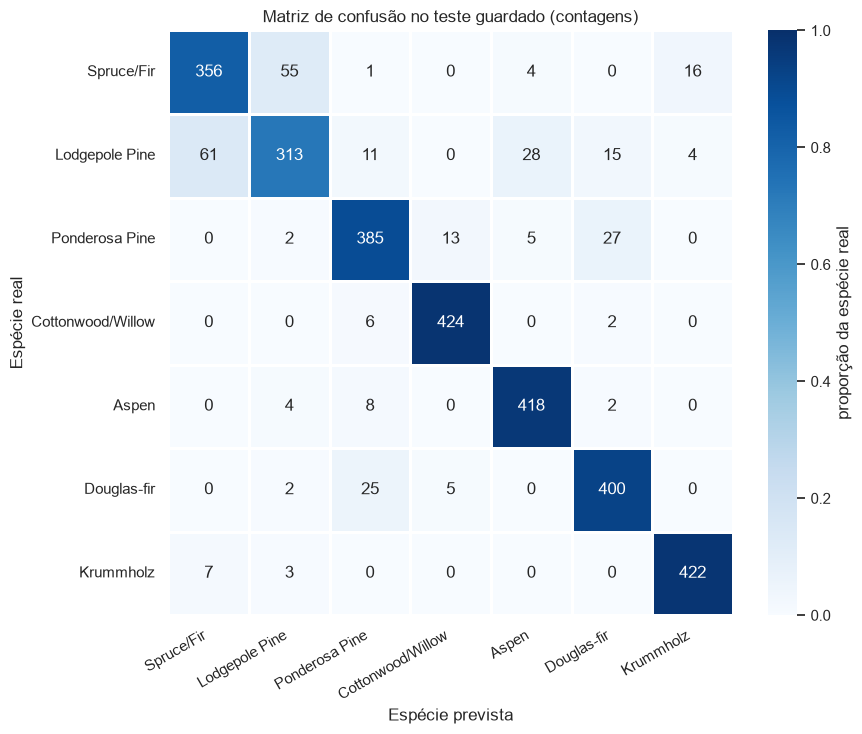

In [57]:
# Matriz de confusão: cor pela proporção da espécie real, número pela contagem
nomes = list(COVER_NAMES.values())
matriz = confusion_matrix(y_test, y_pred, labels=list(COVER_NAMES))
matriz_norm = matriz / matriz.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(matriz_norm, annot=matriz, fmt="d", cmap="Blues", vmin=0, vmax=1,
            xticklabels=nomes, yticklabels=nomes, linewidths=1, linecolor="white",
            cbar_kws={"label": "proporção da espécie real"}, ax=ax)
ax.set_xlabel("Espécie prevista")
ax.set_ylabel("Espécie real")
ax.set_title("Matriz de confusão no teste guardado (contagens)", fontsize=12)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [58]:
# Os pares de espécies mais confundidos (somando os erros nas duas direções)
erros = []
for i in range(7):
    for j in range(i + 1, 7):
        erros.append({"par": f"{nomes[i]} x {nomes[j]}", "erros": matriz[i, j] + matriz[j, i]})
pares_erro = pd.DataFrame(erros).sort_values("erros", ascending=False).head(5).set_index("par")
pares_erro["% de todos os erros"] = (pares_erro["erros"] / (len(y_test) - np.trace(matriz)) * 100).round(1)
pares_erro

,erros,% de todos os erros
par,,
Spruce/Fir x Lodgepole Pine,116,37.9
Ponderosa Pine x Douglas-fir,52,17.0
Lodgepole Pine x Aspen,32,10.5
Spruce/Fir x Krummholz,23,7.5
Ponderosa Pine x Cottonwood/Willow,19,6.2


A matriz confirma a previsão da seção 4.2:

- **Spruce/Fir x Lodgepole Pine:** 38% de todos os erros. Faixas de altitude, áreas e solos parecidos.
- **Ponderosa Pine x Douglas-fir:** 17% dos erros.
- **Cottonwood/Willow e Krummholz:** acima de 97% de acerto (espécies dos extremos).

Os erros quase sempre envolvem espécies vizinhas em altitude.

### 7.3 Métricas por espécie

In [59]:
# Precisão, recall e F1 de cada espécie no teste guardado
print(classification_report(y_test, y_pred, target_names=nomes, digits=3))

                   precision    recall  f1-score   support

       Spruce/Fir      0.840     0.824     0.832       432
   Lodgepole Pine      0.826     0.725     0.772       432
   Ponderosa Pine      0.883     0.891     0.887       432
Cottonwood/Willow      0.959     0.981     0.970       432
            Aspen      0.919     0.968     0.943       432
      Douglas-fir      0.897     0.926     0.911       432
        Krummholz      0.955     0.977     0.966       432

         accuracy                          0.899      3024
        macro avg      0.897     0.899     0.897      3024
     weighted avg      0.897     0.899     0.897      3024



**Lodgepole Pine tem o pior recall (72%)** e Spruce/Fir o segundo pior F1 (0,83). As outras cinco espécies têm F1 acima de 0,88. As duas espécies mais difíceis são justamente as mais comuns na floresta real (seção 7.6).

### 7.4 Curvas ROC um-contra-todos

Uma curva por espécie (essa espécie contra as demais). À direita, ampliação da região de poucos falsos positivos.

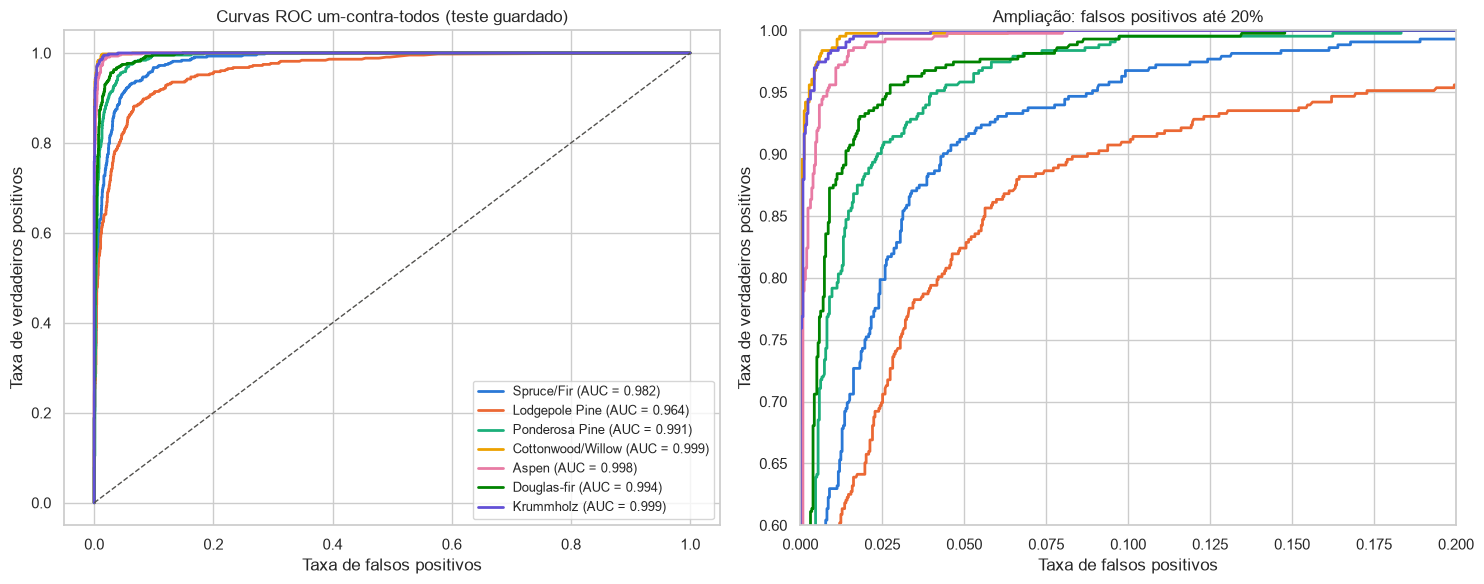

In [60]:
# Uma curva ROC por espécie (um contra todos), com uma ampliação da região de poucos falsos positivos
y_test_bin = label_binarize(y_test, classes=list(COVER_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for k, (classe, nome) in enumerate(COVER_NAMES.items()):
    fpr, tpr, _ = roc_curve(y_test_bin[:, k], y_proba[:, k])
    auc_classe = roc_auc_score(y_test_bin[:, k], y_proba[:, k])
    for ax in axes:
        ax.plot(fpr, tpr, color=CLASS_COLORS[nome], linewidth=2, label=f"{nome} (AUC = {auc_classe:.3f})")

for ax in axes:
    ax.plot([0, 1], [0, 1], color=COR_NEUTRA, linestyle="--", linewidth=1)
    ax.set_xlabel("Taxa de falsos positivos")
    ax.set_ylabel("Taxa de verdadeiros positivos")
axes[0].set_title("Curvas ROC um-contra-todos (teste guardado)", fontsize=12)
axes[0].legend(loc="lower right", fontsize=9)
axes[1].set_xlim(0, 0.2)
axes[1].set_ylim(0.6, 1.0)
axes[1].set_title("Ampliação: falsos positivos até 20%", fontsize=12)
plt.tight_layout()
plt.show()

Todas as espécies têm AUC acima de 0,96. Lodgepole Pine e Spruce/Fir têm as curvas mais baixas. A AUC alta mostra que, mesmo quando erra entre as duas, o modelo dá probabilidade razoável à espécie correta.

### 7.5 Importância das features por permutação

Meço a queda de acurácia ao embaralhar cada coluna, no teste guardado. Embaralho as 52 colunas de entrada; assim, embaralhar `Elevation` também afeta `Elev_Menos_VHidro`, e a importância soma os efeitos diretos e derivados.

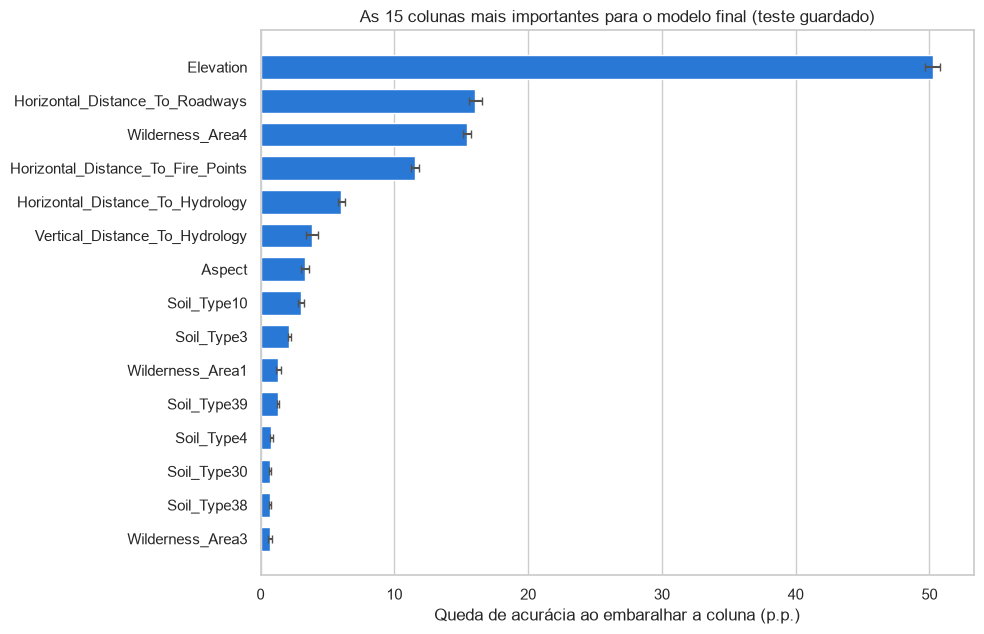

In [61]:
# Queda de acurácia ao embaralhar cada coluna de entrada, repetida 10 vezes, no teste guardado
perm = permutation_importance(modelo_final, X_test, y_test, scoring="accuracy",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importancias = pd.DataFrame({
    "queda média de acurácia": perm.importances_mean,
    "desvio": perm.importances_std,
}, index=X_test.columns).sort_values("queda média de acurácia", ascending=False)

top_imp = importancias.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top_imp.index, top_imp["queda média de acurácia"] * 100, xerr=top_imp["desvio"] * 100,
        color=CLASS_COLORS["Spruce/Fir"], height=0.7, error_kw={"ecolor": COR_NEUTRA, "capsize": 3})
ax.set_xlabel("Queda de acurácia ao embaralhar a coluna (p.p.)")
ax.set_title("As 15 colunas mais importantes para o modelo final (teste guardado)", fontsize=12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [62]:
# Colunas cuja permutação não altera a acurácia (importância menor que 0,1 p.p.)
irrelevantes = importancias[importancias["queda média de acurácia"].abs() < 0.001]
print(f"{len(irrelevantes)} das {len(importancias)} colunas têm importância praticamente nula")
print("Destas, tipos de solo:", sum(c.startswith("Soil_Type") for c in irrelevantes.index))

18 das 52 colunas têm importância praticamente nula
Destas, tipos de solo: 18


- **Elevação domina:** embaralhá-la derruba a acurácia em ~50 p.p.
- **Distâncias até estradas e pontos de ignição** e **`Wilderness_Area4`** completam as quatro mais importantes.
- **18 colunas, todas tipos de solo, têm importância nula.** Removê-las exigiria novo teste, porque a permutação subestima colunas redundantes.

### 7.6 Do teste guardado ao teste do Kaggle: a distribuição das classes muda

O treino é balanceado, mas o teste do Kaggle segue a distribuição real da floresta. Reconstruo essa distribuição com os totais por espécie do dataset Covertype original (sem usar nenhum rótulo individual) e estimo a acurácia esperada ponderando o recall de cada espécie pela sua frequência real.

In [63]:
# Total de linhas por espécie no dataset Covertype original (UCI, 581.012 linhas)
TOTAL_ORIGINAL = pd.Series({1: 211_840, 2: 283_301, 3: 35_754, 4: 2_747, 5: 9_493, 6: 17_367, 7: 20_510})
teste_kaggle_real = TOTAL_ORIGINAL - y.value_counts().sort_index()  # remove as linhas do train.csv
print("Linhas no teste do Kaggle reconstruídas:", teste_kaggle_real.sum())

recall_por_classe = pd.Series(np.diag(matriz) / matriz.sum(axis=1), index=list(COVER_NAMES))
proporcao_real = teste_kaggle_real / teste_kaggle_real.sum()

distribuicao = pd.DataFrame({
    "espécie": nomes,
    "% no train.csv": 100 / 7,
    "% real no teste do Kaggle": proporcao_real * 100,
    "recall no teste guardado (%)": recall_por_classe * 100,
}, index=list(COVER_NAMES)).round(2)
distribuicao

Linhas no teste do Kaggle reconstruídas: 565892


,espécie,% no train.csv,% real no teste do Kaggle,recall no teste guardado (%)
1,Spruce/Fir,14.29,37.05,82.41
2,Lodgepole Pine,14.29,49.68,72.45
3,Ponderosa Pine,14.29,5.94,89.12
4,Cottonwood/Willow,14.29,0.10,98.15
5,Aspen,14.29,1.30,96.76
6,Douglas-fir,14.29,2.69,92.59
7,Krummholz,14.29,3.24,97.69


In [64]:
acuracia_esperada = (recall_por_classe * proporcao_real).sum()

# Erro padrão da estimativa: cada recall foi medido em 432 linhas e entra com o peso da classe
n_por_classe = matriz.sum(axis=1)
erro_esperada = np.sqrt((proporcao_real**2 * recall_por_classe * (1 - recall_por_classe) / n_por_classe).sum())

print(f"Acurácia no teste guardado (classes balanceadas): {metricas_teste['acurácia']:.2%}")
print(f"Acurácia esperada com a distribuição real do teste do Kaggle: {acuracia_esperada:.2%} "
      f"(IC 95%: {acuracia_esperada - 1.96 * erro_esperada:.2%} a {acuracia_esperada + 1.96 * erro_esperada:.2%})")

Acurácia no teste guardado (classes balanceadas): 89.88%
Acurácia esperada com a distribuição real do teste do Kaggle: 78.83% (IC 95%: 76.34% a 81.32%)


**Acurácia esperada no Kaggle: ~79%** (IC 95%: 76,3% a 81,3%), 10 p.p. abaixo do teste guardado, com o mesmo modelo. Spruce/Fir e Lodgepole Pine são **87% do teste do Kaggle** e são as duas espécies mais difíceis. No treino balanceado, elas são só 2/7.

### 7.7 Submissão ao Kaggle

Retreino o pipeline final com todo o `train.csv` (15.120 linhas): o teste guardado já cumpriu seu papel, e mais dados só ajudam.

In [65]:
if df_test_kaggle is None:
    raise FileNotFoundError("data/test.csv não encontrado: a submissão ao Kaggle precisa dele (ver README).")

# Retreino com as 15.120 linhas rotuladas (treino + teste guardado)
modelo_submissao = clone(modelo_final).fit(X, y)

previsao_kaggle = modelo_submissao.predict(df_test_kaggle.drop(columns=COLS_REMOVIDAS))
submissao = pd.DataFrame({"Id": df_test_kaggle["Id"], "Cover_Type": previsao_kaggle})

# Confere o formato com o arquivo de exemplo da competição
exemplo = pd.read_csv(DATA_DIR / "sampleSubmission.csv")
assert list(submissao.columns) == list(exemplo.columns) and len(submissao) == len(exemplo)
assert submissao["Id"].equals(exemplo["Id"])

submissao.to_csv("submission.csv", index=False)
print(f"submission.csv salvo: {len(submissao)} linhas")
submissao.head()

submission.csv salvo: 565892 linhas


,Id,Cover_Type
0,15121,1
1,15122,1
2,15123,1
3,15124,1
4,15125,1


In [66]:
# Distribuição das previsões no teste do Kaggle comparada à distribuição real
pd.DataFrame({
    "espécie": nomes,
    "% prevista": submissao["Cover_Type"].value_counts(normalize=True).sort_index() * 100,
    "% real": proporcao_real * 100,
}, index=list(COVER_NAMES)).round(2)

,espécie,% prevista,% real
1,Spruce/Fir,37.11,37.05
2,Lodgepole Pine,42.87,49.68
3,Ponderosa Pine,6.44,5.94
4,Cottonwood/Willow,0.32,0.10
5,Aspen,4.51,1.30
6,Douglas-fir,3.99,2.69
7,Krummholz,4.76,3.24


Como aprendeu com classes balanceadas, o modelo prevê espécies raras em excesso (Aspen 3,5 vezes acima do real) e Lodgepole Pine de menos.

**Resultado da submissão (late submission):**

| Nota pública | Nota privada |
|---|---|
| **0,80579** | **0,80579** |

A nota ficou dentro do intervalo estimado na seção 7.6. A queda de ~90% para ~80% vem da mudança na distribuição das classes, não de sobreajuste.

## 8. Conclusão e próximos passos

### Resumo dos achados

**Resultado:** Extra Trees com **89,9%** de acurácia no teste guardado e **0,80579** no Kaggle, contra 14,3% do baseline.

1. **A altitude é o principal fator:** as espécies se organizam em faixas de altitude.
2. **Distâncias até estradas e pontos de ignição funcionam como pistas de localização**, e suas somas e diferenças foram as features que mais ajudaram.
3. **Engenharia de features rendeu mais que ajuste de hiperparâmetros:** +3,7 p.p. contra +0,4 p.p. no Extra Trees.
4. **Modelos de árvore são os mais adequados:** as fronteiras são não lineares e fragmentadas (logística ~71%, KNN ~80%, árvores acima de 87%).
5. **Os erros se concentram em espécies vizinhas em altitude:** Spruce/Fir x Lodgepole Pine e Ponderosa Pine x Douglas-fir.
6. **A nota do Kaggle é menor por causa da distribuição das classes**, não de sobreajuste, e foi prevista antes da submissão.

Validação cruzada (89,5%) e teste guardado (89,9%) praticamente iguais confirmam que o pipeline não teve vazamento de dados.

### Próximos passos

1. **Ajustar as probabilidades à distribuição real das classes** (por exemplo, com o algoritmo EM de Saerens et al., 2002), para reduzir o excesso de espécies raras previstas.
2. **Modelo especializado em Spruce/Fir x Lodgepole Pine**, o par que concentra os erros.
3. **Ajustar o boosting** (HistGradientBoosting, LightGBM, XGBoost) e testar *stacking*.
4. **Validação cruzada aninhada**, para medir sem viés o ganho do ajuste de hiperparâmetros.
5. **Refinar features:** imputar os 16 zeros suspeitos de `Hillshade_3pm`, agrupar solos raros e testar novas combinações de distâncias.
6. **Validar em outra região**, para separar padrões ecológicos gerais da memorização da geografia local.

## 9. Reprodutibilidade

As versões usadas estão abaixo e fixadas no `requirements.txt`. O passo a passo completo está no `README.md`.

In [67]:
# Versões do ambiente em que este notebook foi executado
import platform
import sys

import joblib
import matplotlib
import scipy
import sklearn

versoes = {
    "Python": sys.version.split()[0],
    "Sistema": f"{platform.system()} {platform.machine()}",
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "joblib": joblib.__version__,
}
pd.Series(versoes, name="versão").to_frame()

,versão
Python,3.12.9
Sistema,Darwin arm64
numpy,2.5.5
pandas,3.1.1
scikit-learn,1.9.1
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2
joblib,1.6.0


**Como reproduzir:**

1. Python 3.11 ou superior; `pip install -r requirements.txt`.
2. Baixar os dados com a CLI do Kaggle para `data/` (token em `~/.kaggle/access_token`).
3. Executar **Kernel → Restart & Run All** (cerca de 4 a 5 minutos).

**Por que os resultados são idênticos a cada execução:**

- `RANDOM_STATE = 42` em toda aleatoriedade (divisão, folds, modelos, busca, permutação);
- o paralelismo (`n_jobs=-1`) muda só a velocidade, não os números;
- todas as transformações estão no `Pipeline`, sem passos manuais;
- o único dado externo (totais por espécie do Covertype, seção 7.6) está escrito no código.

O notebook gera o `submission.csv` (fora do repositório), enviado com `kaggle competitions submit -c forest-cover-type-prediction -f submission.csv -m "mensagem"`.